# Phase 1: Perception

## Section 1 - Purpose and overview

This notebook is the first phase of the thesis pipeline: it recognizes the pieces of an assembly in egocentric frames recorded with an XR headset. Mr Potato Head is used as a proxy for an industrial assembly, with 10 pieces, a clear procedure and fully controllable recordings. The next phases build on this one: phase 2 tracks which pieces are mounted and in which order, and phase 3 checks the sequence against the assembly rules. For this, perception must say not only which pieces are in the frame but also where they are. The notebook therefore works at patch level: every 16x16 patch of the frame gets a class.

No model is trained. Only a few annotated frames are available for each piece, and retraining a model on so few examples would overfit (Snell et al. 2017, Sect. 1). C-RADIOv4-SO400M is used instead as a frozen feature extractor, the use its authors intend for downstream tasks, including dense ones such as segmentation (model card). Each frame becomes a 64x64 grid of patches, each described by a 1152-dimensional vector. Each class is represented by a prototype, the mean of its annotated patches in a few reference frames, and a new patch takes the class of the most similar prototype. This is the idea behind prototypical networks (Snell et al. 2017, Sect. 1) and the nearest class mean classifier (Mensink et al. 2013). It also means that a new class only needs its own mean: Mensink et al. study classifiers that can add new classes at negligible cost, which matters when the pieces of a real assembly change. The classes are the 10 pieces, the background, and the hand. Hands are annotated so that they do not end up in other prototypes, but they are never reported as a piece. A margin sends uncertain pieces to background.

This notebook reads only validation frames and evaluates them qualitatively. The quantitative evaluation (per-class IoU) is done in the support-set study, which also selected the reference frames used here. The test sequence is held out until the end of all studies.

Structure: configuration (2); model and features (3); dataset and split (4); from annotations to patch labels (5); prototypes (6); support-set gallery (7); prototype similarity (8); classifier (9); qualitative evaluation on validation frames (10); video pipeline (11); latency (12); limitations; sensitivity checks (Appendix A). Each section opens with a short introduction to its choices and ends with observations and references. Provisional values are marked as such in Section 2.

## Section 2 - Configuration

All paths, classes and hyperparameters in one place. Provisional values are marked as such.

In [1]:
# 2.1 Dependencies: install once per environment with pip install -r requirements.txt (README, Setup)

In [2]:
# 2.2 Imports 
import json
import sys
import time
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
from sklearn.decomposition import PCA
import transformers


In [3]:
# 2.3 Paths and shared module
# One single project root. In this way the notebook can be executed everywhere
# Separated outputs per notebook
# Folder existence check
PROJECT_ROOT = Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))   # makes src/perception importable from notebooks/

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
FRAMES_DIR = PROJECT_ROOT / "data" / "extracted_frames"
VIDEOS_DIR = PROJECT_ROOT / "data" / "raw_videos"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "phase_1_perception"
PROTOTYPES_PATH = OUTPUT_DIR / "patch_prototypes.npz"     # V2 prototypes (the old prototypes.npz held the V0 class means)
ANNOTATION_ARCHIVE = PROJECT_ROOT / "data" / "annotation_versions" / "margin_study"   # caos_f0211 as used by the studies

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for name, path in {"MODEL_DIR": MODEL_DIR, "FRAMES_DIR": FRAMES_DIR, "VIDEOS_DIR": VIDEOS_DIR, "SRC_DIR": SRC_DIR,
                   "ANNOTATION_ARCHIVE": ANNOTATION_ARCHIVE}.items():
    status = "OK" if path.exists() else "MISSING"
    print(f"[{status}] {name}: {path}")

# Shared code (src/perception), used by every Phase 1 notebook
from perception.features import FeatureExtractor
from perception.labels import sequence_of, check_annotation, rasterize_annotation, patch_label_grid, load_annotation
from perception.prototypes import (l2_normalize, build_prototypes, stack_prototypes,      # class means: diagnostics only (Section 8)
                                   patch_prototypes, sort_by_class, class_similarities_gpu, assign_labels,
                                   save_patch_prototypes, load_patch_prototypes)
from perception.metrics import confusion_matrix, frame_iou, frame_miou
from perception.visualization import label_grid_to_rgb, render_overlay

[OK] MODEL_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\models\c_radio_weights
[OK] FRAMES_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\extracted_frames
[OK] VIDEOS_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\raw_videos
[OK] SRC_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\src
[OK] ANNOTATION_ARCHIVE: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\annotation_versions\margin_study


In [4]:
# 2.4 Official class list, defined once in src/perception/classes.py and shared by all notebooks.
# Annotations are checked against it in Section 4, and its order fixes the color of each class in every plot.
from perception.classes import (CLASS_NAMES, BACKGROUND_LABEL, HAND_LABEL, PIECE_LABELS, IGNORE_ID, PATCH_LABEL_NAMES, CLASS_COLORS)

print(f"{len(CLASS_NAMES)} classes: {CLASS_NAMES}")


12 classes: ['background', 'body', 'base', 'hat', 'eyes', 'ear', 'nose', 'moustache', 'mouth', 'arm_1', 'arm_2', 'hand']


In [5]:
# 2.5 Hyperparameters
# Each parameter is listed with the section that uses it.

# --- Feature extraction (Section 3) ---
DEVICE = "cuda"
DTYPE = torch.bfloat16

# --- PCA visualization (Section 3, visualization only) ---
PCA_N_COMPONENTS = 3
PCA_BORDER_EXCLUDE = 2          # patches excluded on each side when fitting the PCA
PCA_CLIP_PERCENTILES = (1, 99)

# --- Patch labelling (Section 5) ---
MIN_LABEL_COVERAGE = 0.5        # a patch gets a class label (piece or hand) if that class covers at least this fraction of it

# --- Border-artifact check (Sections A.2 and 10) ---
EXTREME_NORM_FACTOR = 5         # diagnostic only: a patch is "extreme" if its norm exceeds 5x the median patch norm

# --- Support-set gallery (Section 7, visualization only) ---
GALLERY_MARGIN = 1              # extra patches shown around each crop
GALLERY_DIM_FACTOR = 0.35       # brightness of pixels outside the patches used for the prototype

# --- Classification (Section 9) ---
MARGIN = 0.0                    # background margin of V2: each patch takes its most similar class (margin study, Section 9)

# --- Independent frame (Section 10.4) ---
INDEPENDENT_FRAME = FRAMES_DIR / "frame_1.jpeg"   # iPhone, wide angle: different camera from the headset
INDEPENDENT_MAX_SIDE = 1024                        # longer side resized to the headset resolution

# --- Video pipeline (Section 11) ---
MOTION_THRESHOLD = 1.0          # provisional: mean absolute gray-level difference (0-255) between consecutive frames
STABLE_FRAMES_NEEDED = 5        # provisional: consecutive still frames before running C-RADIO (~167 ms at 30 fps)
MIN_BLOB_PATCHES = 5            # smallest blob that gets a text label in the overlays (Sections 10–11)
MOTION_SIZE = (320, 320)        # provisional: frames are downscaled before computing the motion score

# --- Reproducibility ---
RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)
_ = torch.manual_seed(RANDOM_SEED)

In [6]:
# 2.6 Environment
print(f"Python       : {platform.python_version()}")
print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"CUDA         : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")

Python       : 3.10.0
PyTorch      : 2.5.1+cu121
Transformers : 5.17.0
CUDA         : True
GPU          : NVIDIA GeForce RTX 4060 Laptop GPU


------------------------------------------------------------------------------------------------------------------------------------------

References Section 2: none. The environment printed in 2.6 will be reported in the thesis (Experimental setup).

------------------------------------------------------------------------------------------------------------------------------------------

## Section 3 - Model and feature extraction

This section turns each frame into features.

C-RADIOv4-SO400M is an agglomerative vision model: it was trained by distillation to reproduce, in a single backbone, the features of several foundation models (SigLIP2, DINOv3 and SAM3), keeping their different strengths (C-RADIOv4 tech report, Abstract, Sect. 1 and 2.1). Its authors present it as a feature extractor for downstream tasks, including dense ones such as semantic segmentation (model card), and this is how it is used here: frozen, without training or fine-tuning.

Like every Vision Transformer, the model cuts the image into fixed-size patches and describes each patch with one vector (Dosovitskiy et al. 2021, Sect. 3.1). Here the patches are 16x16 pixels and the vectors have 1152 dimensions.

Frames are used at their native resolution, 1024x1024, which is one of the resolutions the model was trained on (tech report, Sect. 2.2). Lower resolutions have not been studied yet.

Two details of the input are checked explicitly (3.2, 3.3), because a mistake there would change the features without raising any error: the pixels must be rescaled to [0, 1] and normalized exactly once.

Finally, the features of one frame are shown as a patch grid (3.5) and as colors through a PCA projection (3.6), the visualization used by DINOv2 and by the C-RADIOv4 authors (Oquab et al. 2024, Sect. 7.5; tech report, Fig. 1).

In [7]:
# 3.1 Loading the model
# Model in inference mode on GPU. The patch size (16x16) is read by the model
t0 = time.time()
extractor = FeatureExtractor(MODEL_DIR, device=DEVICE, dtype=DTYPE)
torch.cuda.synchronize()
print(f"Model loaded in {time.time() - t0:.2f}s")

model, image_processor = extractor.model, extractor.image_processor   # inspected directly in 3.2, 3.3, A.2
PATCH_SIZE = extractor.patch_size
print(f"Patch size: {PATCH_SIZE}x{PATCH_SIZE} pixels")


Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

Model loaded in 5.78s
Patch size: 16x16 pixels


In [8]:
# 3.2 What the preprocessor does
# The preprocessor rescales the pixels in [0,1] and does not normalize (do_normalize: false). 
print(image_processor)

CLIPImageProcessor {
  "crop_size": {
    "height": 512,
    "width": 512
  },
  "do_center_crop": false,
  "do_convert_rgb": true,
  "do_normalize": false,
  "do_rescale": true,
  "do_resize": false,
  "image_mean": [
    0.48145466,
    0.4578275,
    0.40821073
  ],
  "image_processor_type": "CLIPImageProcessor",
  "image_std": [
    0.26862954,
    0.26130258,
    0.27577711
  ],
  "resample": 3,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "shortest_edge": 512
  }
}



In [9]:
# 3.3 Who does the input normalization? It is internal to the model (input conditioner):
# per-channel (x - mean) / std with the CLIP constants, applied after the preprocessor's [0, 1] rescaling.
conditioner = model.radio_model.input_conditioner
for name, value in conditioner.named_buffers():
    print(f"{name}: {value.flatten().tolist()}")

norm_mean: [0.48145467042922974, 0.45782750844955444, 0.40821072459220886]
norm_std: [0.2686295509338379, 0.2613025903701782, 0.27577710151672363]


3.4 Feature extraction.

Input: the RGB frame (1024x1024), with pixel values rescaled to [0, 1] by the preprocessor, in bfloat16. bfloat16 is less precise than float32 but faster on the GPU, and it is the precision the model was trained with (config.json, amp_dtype).

Normalization: per-channel (x − mean) / std with the CLIP constants (mean 0.481, 0.458, 0.408; std 0.269, 0.261, 0.276), done inside the model by its input conditioner (3.3). The preprocessor configuration also lists these constants (3.2), but it does not apply them because do_normalize is false. The image is therefore normalized only once.

Output: one 1152-dimensional vector per 16x16 patch, a 64x64 grid of 4096 vectors. The global summary vector is not used, since the method works at patch level.

In [10]:
# 3.4 Feature extraction (FeatureExtractor.extract in src/perception/features.py)
EXAMPLE_FRAME = FRAMES_DIR / "3_disassembled_ordered_f0001.jpg"

example_image = Image.open(EXAMPLE_FRAME).convert("RGB")
example_features, example_resized_size = extractor.extract(example_image)
h_patches, w_patches, feat_dim = example_features.shape

print(f"Original size  : {example_image.width}x{example_image.height}")
print(f"Model input    : {example_resized_size[0]}x{example_resized_size[1]}")
print(f"Patch grid     : {w_patches}x{h_patches} = {w_patches * h_patches} patches")
print(f"Feature dim D  : {feat_dim}")

Original size  : 1024x1024
Model input    : 1024x1024
Patch grid     : 64x64 = 4096 patches
Feature dim D  : 1152


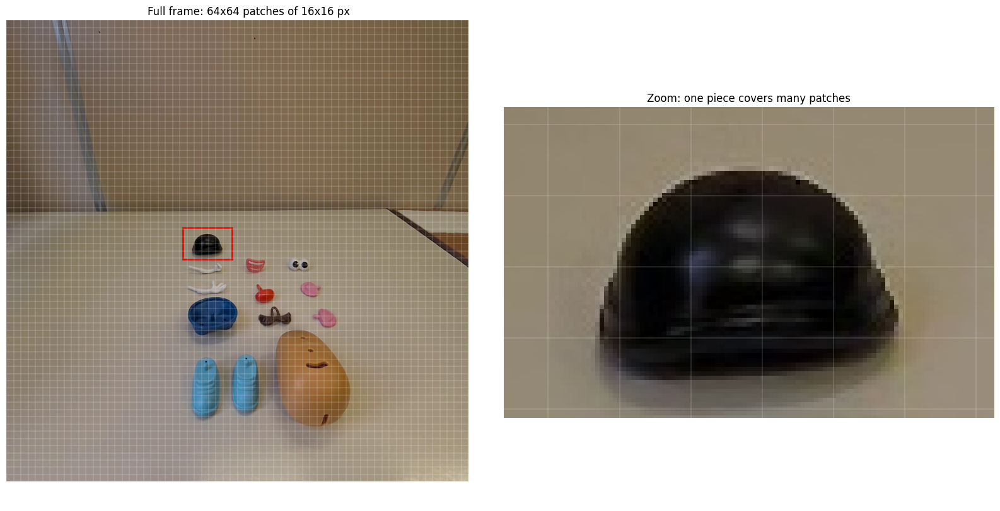

In [11]:
# 3.5 Patch grid
# What is a patch from a visual point of view. 
# A piece covers a lot of patches
# The edge patches are mixed
ZOOM_BOX = (390, 460, 500, 530)  # (x0, y0, x1, y1) in model-input pixels: adjust to frame one piece

example_resized = example_image.resize(example_resized_size, Image.Resampling.LANCZOS)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax in axes:
    ax.imshow(example_resized)
    for x in range(0, example_resized_size[0] + 1, PATCH_SIZE):
        ax.axvline(x, color="white", linewidth=0.3, alpha=0.6)
    for y in range(0, example_resized_size[1] + 1, PATCH_SIZE):
        ax.axhline(y, color="white", linewidth=0.3, alpha=0.6)
    ax.axis("off")

x0, y0, x1, y1 = ZOOM_BOX
axes[0].add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", linewidth=2))
axes[0].set_title(f"Full frame: {w_patches}x{h_patches} patches of {PATCH_SIZE}x{PATCH_SIZE} px")
axes[1].set_xlim(x0, x1)
axes[1].set_ylim(y1, y0)  # image y axis points down
axes[1].set_title("Zoom: one piece covers many patches")
plt.tight_layout()
plt.show()

Observation 3.5: The hat, one of the larger loose pieces, spans only a few patches in each direction, and the patches on its outline contain both hat and table. Smaller pieces cover even fewer patches. These mixed patches are the reason for the labelling rule of Section 5.

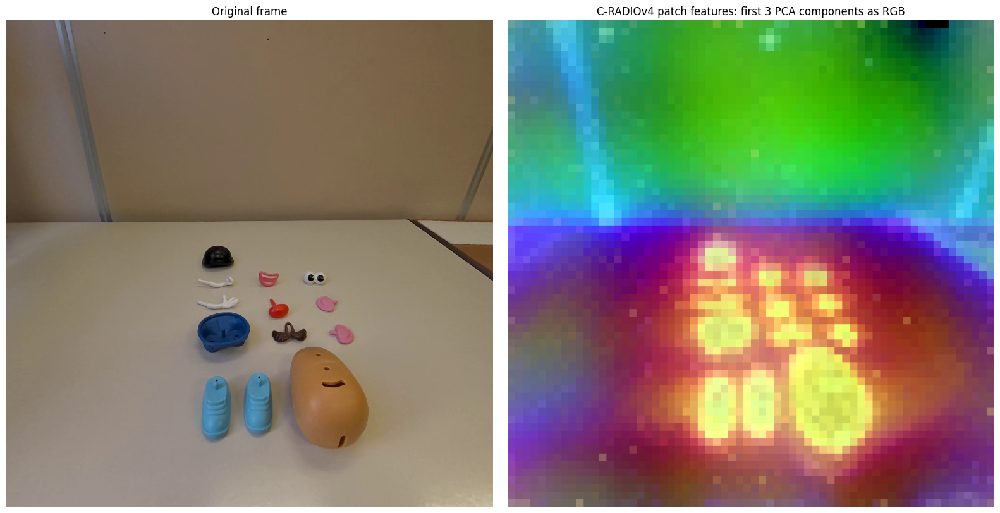

Variance explained by each component: [0.165 0.087 0.068] (total 31.9%)


In [12]:
# 3.6 Feature PCA
# Projection of the 1152 dimension on 3 to visualize them as RGB
def pca_to_rgb(features, border=PCA_BORDER_EXCLUDE, clip=PCA_CLIP_PERCENTILES, seed=RANDOM_SEED):
    """Project patch features onto their first 3 principal components and map them to RGB.
    Visualization only: the classifier always uses the full D-dimensional features."""
    h, w, d = features.shape
    fit_on = features[border:h - border, border:w - border].reshape(-1, d)
    pca = PCA(n_components=PCA_N_COMPONENTS, random_state=seed).fit(fit_on)
    projected = pca.transform(features.reshape(-1, d))
    low, high = np.percentile(projected, clip, axis=0)
    rgb = np.clip((projected - low) / (high - low + 1e-8), 0, 1)
    return rgb.reshape(h, w, 3), pca.explained_variance_ratio_


pca_rgb, explained = pca_to_rgb(example_features)
pca_rgb_full = cv2.resize(pca_rgb, example_image.size, interpolation=cv2.INTER_NEAREST)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(example_image)
axes[0].set_title("Original frame")
axes[1].imshow(pca_rgb_full)
axes[1].set_title("C-RADIOv4 patch features: first 3 PCA components as RGB")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print(f"Variance explained by each component: {explained.round(3)} (total {explained.sum():.1%})")

Observation 3.6: The first three principal components separate the main regions of the frame: wall, table and objects take three different colors. All the pieces take a similar yellow-orange color, so these components do not tell one piece from another, and together they explain only 31.9% of the variance. The PCA is therefore only a visualization: classification uses all 1152 dimensions.

DINOv2 reports the same behaviour, with the first component separating objects from background (Oquab et al. 2024, Sect. 7.5).

Around each piece the color spreads slightly onto the table, which may be related to the predicted pieces being slightly larger than the real ones (10.1).

The dark patch in the top-right corner is a model artifact (A.2): this is why border patches are excluded from the PCA fit.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 3:

C-RADIOv4-SO400M, Hugging Face model card (nvidia/C-RADIOv4-SO400M, commit c0457f5, accessed October 2026): frozen feature extractor for downstream tasks, including dense tasks such as semantic segmentation (Description, Use Case) 3.1; output = summary + one feature vector per patch, reshaped to a grid with patch size 16 (Usage) 3.4; input resolutions tested from 256 to 2048 in steps of 16 pixels (Input; Explainability, Technical Limitations) 3.4.

C-RADIOv4-SO400M model files, same commit: preprocessor_config.json (do_rescale: true, do_normalize: false) 3.2; input_conditioner.py and radio_model.py, forward (per-channel (x - mean) / std inside the model, input expected in [0, 1]) 3.3; radio_model.py, get_nearest_supported_resolution (rounds to the nearest multiple of the patch size) 3.4; config.json (patch_size: 16; trained with amp_dtype: bfloat16) 3.1, 3.4; hf_model.py (patch_size read from the model) 3.1.

C-RADIOv4 tech report (Ranzinger et al. 2026): agglomerative model distilled from SigLIP2, DINOv3 and SAM3 (Abstract, Sect. 1 and 2.1) 3.1; 1024 among the training resolutions (Sect. 2.2) 3.4; PCA visualization of the features (Fig. 1) 3.6.

Dosovitskiy et al. 2021, An Image is Worth 16x16 Words (ViT), Sect. 3.1: the image is split into fixed-size patches, each mapped to one vector 3.5.

Oquab et al. 2024, DINOv2, Sect. 7.5 (Fig. 1 and 9): PCA of patch features, the first component separates objects from background 3.6.



------------------------------------------------------------------------------------------------------------------------------------------

## Section 4 - Dataset

This section defines which frames are used and for what.

The reference frames are the support set, the few annotated examples the prototypes are built from (Snell et al. 2017, Sect. 2.1). The ten frames were selected in the support-set studies: they cover every piece loose and mounted, plus two poses of the base and one frame for the hands (support-set study on V2, Sect. 5 and 11). Two frames were added by the coverage rule of the multi-prototype study: caos_f0043 teaches the mouth seen from the side, and 4_partially_assembled_f0002 the body with the empty mouth slot and a mouth seen at three quarters.

Each frame declares which classes it teaches (use_labels). Other polygons are ignored, not counted as background: for example, the pieces in the hands frame. The old shoe and pants labels are always ignored. caos_f0211 is read from the archived annotation used by the studies, so that the prototypes are exactly those that were evaluated.

Frames are split by recording, because consecutive frames are almost identical and would inflate the results. Assembly101 also splits its data by recording (Sener et al. 2022, Sect. 4.6).

Validation is 32 frames of assembly_2: 10 at the table, 11 at a pick and 11 at a mounting, chosen with rules from the event log (support-set study on V2, Sect. 3). They were used to choose the method and the support set, so their values are optimistic: a model chosen on a set is evaluated with a bias in its favour on the same set (Cawley and Talbot 2010, Sect. 5). The test sequence (assembly_1) is held out until the end of Phase 1 and never read here.

In [13]:
# 4.1 Reference frames: the support set selected in the support-set studies (support-set study on V2, Section 11)
# Each reference frame declares which classes it contributes to the prototypes.
# Annotated polygons with any other label are ignored (neither used nor counted as background).
REFERENCE_FRAMES = [
    {"frame": "5_assembled_f0002",            "role": "assembled",                   "use_labels": PIECE_LABELS},
    {"frame": "caos_f0149",                   "role": "partially assembled",         "use_labels": PIECE_LABELS},
    {"frame": "5_assembled_f0019",            "role": "assembled, 3/4 view",         "use_labels": PIECE_LABELS},
    {"frame": "3_disassembled_ordered_f0001", "role": "disassembled",                "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "2_disassembled_caos_f0016",    "role": "disassembled, top-down view", "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "Take_3_1_Base_f0099",          "role": "base only, upright",          "use_labels": {"base"}},
    {"frame": "Take_3_1_Base_f0131",          "role": "base only, lying",            "use_labels": {"base"}},
    {"frame": "caos_f0211",                   "role": "hands",                       "use_labels": {HAND_LABEL},
     "json_path": ANNOTATION_ARCHIVE / "caos_f0211.json"},
    {"frame": "4_partially_assembled_f0002",  "role": "body on base, face incomplete; mouth loose at 3/4",
     "use_labels": {"body", "mouth"}},
    {"frame": "caos_f0043",                   "role": "mouth loose, side view",      "use_labels": {"mouth"}},
]
assert len(REFERENCE_FRAMES) == 10

for ref in REFERENCE_FRAMES:
    ref["image_path"] = FRAMES_DIR / f"{ref['frame']}.jpg"
    ref["json_path"] = ref.get("json_path") or FRAMES_DIR / f"{ref['frame']}.json"
    ref["sequence"] = sequence_of(ref["frame"])

In [14]:
# 4.2 Annotation check
# Automatic verification of file, dimensions and labels
# The table documents where each prototype comes from.
rows = []
for ref in REFERENCE_FRAMES:
    annotated = check_annotation(ref["image_path"], ref["json_path"])

    ref["used_labels"] = annotated & ref["use_labels"]
    rows.append({
        "frame": ref["frame"],
        "sequence": ref["sequence"],
        "role": ref["role"],
        "used": ", ".join(sorted(ref["used_labels"])),
        "ignored": ", ".join(sorted(annotated - ref["use_labels"])) or "-",
    })

display(pd.DataFrame(rows))

print("\nFrames contributing to each class:")
for label in sorted(PIECE_LABELS | {HAND_LABEL}):
    frames = [ref["frame"] for ref in REFERENCE_FRAMES if label in ref["used_labels"]]
    print(f"  {label:<10} {len(frames)} frame(s): {', '.join(frames) if frames else '— NONE'}")

,frame,sequence,role,used,ignored
0,5_assembled_f0002,5_assembled,assembled,"arm_1, arm_2, base, body, ear, eyes, hat, mous...",-
1,caos_f0149,caos,partially assembled,"arm_1, base, body, ear, eyes, hat, moustache, ...",-
2,5_assembled_f0019,5_assembled,"assembled, 3/4 view","arm_1, arm_2, base, body, ear, eyes, hat, mous...",-
3,3_disassembled_ordered_f0001,3_disassembled_ordered,disassembled,"arm_1, arm_2, body, ear, eyes, hat, moustache,...","pants, shoe"
4,2_disassembled_caos_f0016,2_disassembled_caos,"disassembled, top-down view","arm_1, arm_2, body, ear, eyes, hat, moustache,...","pants, shoe"
5,Take_3_1_Base_f0099,Take_3_1_Base,"base only, upright",base,-
6,Take_3_1_Base_f0131,Take_3_1_Base,"base only, lying",base,-
7,caos_f0211,caos,hands,hand,"body, ear, eyes, hat, moustache, nose, pants, ..."
8,4_partially_assembled_f0002,4_partially_assembled,"body on base, face incomplete; mouth loose at 3/4","body, mouth","arm_1, arm_2, base, ear, eyes, hat, moustache,..."
9,caos_f0043,caos,"mouth loose, side view",mouth,"arm_1, arm_2, base, body, ear, eyes, hand, hat..."



Frames contributing to each class:
  arm_1      5 frame(s): 5_assembled_f0002, caos_f0149, 5_assembled_f0019, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  arm_2      4 frame(s): 5_assembled_f0002, 5_assembled_f0019, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  base       5 frame(s): 5_assembled_f0002, caos_f0149, 5_assembled_f0019, Take_3_1_Base_f0099, Take_3_1_Base_f0131
  body       6 frame(s): 5_assembled_f0002, caos_f0149, 5_assembled_f0019, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016, 4_partially_assembled_f0002
  ear        5 frame(s): 5_assembled_f0002, caos_f0149, 5_assembled_f0019, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  eyes       5 frame(s): 5_assembled_f0002, caos_f0149, 5_assembled_f0019, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  hand       1 frame(s): caos_f0211
  hat        5 frame(s): 5_assembled_f0002, caos_f0149, 5_assembled_f0019, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  moustac

Observation 4.2: Every piece is covered by at least 4 reference frames. arm_2 has 4 (only one arm is visible in caos_f0149), most pieces 5, body 6 and mouth 7: 4_partially_assembled_f0002 adds body and mouth, and caos_f0043 adds the mouth seen from the side. Hand comes from a single frame, caos_f0211.

The table also shows what each frame ignores: shoe and pants in the two disassembled frames, all the pieces in the hands frame, and the pieces that 4_partially_assembled_f0002 and caos_f0043 do not teach.

The two mouth frames entered the support set in the multi-prototype study, by the coverage rule: the loose mouth seen from the side, and the body on the base with the empty mouth slot (multi-prototype study, Sect. 1). There they already improved one prototype per class (+0.017 with the arms merged, Obs. 5.2). With V2 they matter more: without them the mIoU over 10 pieces falls from 0.779 to 0.754 and the IoU of the mouth from 0.662 to 0.514 (scratch_working_distance, Section 7).

In [15]:
# 4.3 Sequence split against temporal data leakage.
# Validation: assembly_2, 32 frames chosen with rules from the event log (support-set study on V2, Section 3).
# Test: held out, never read by this notebook; used once, at the end of Phase 1.
# assembly_1 was inspected once, in the qualitative evaluation of v1-baseline (git tag), before any change to the method.
# Of assembly_1, only frame f0073 is annotated.
VALIDATION_SEQUENCES = {"assembly_2"}
TEST_SEQUENCES = {"assembly_1"}
assert not VALIDATION_SEQUENCES & TEST_SEQUENCES, "A sequence cannot be both validation and test"

reference_sequences = {ref["sequence"] for ref in REFERENCE_FRAMES}
leaked = reference_sequences & (VALIDATION_SEQUENCES | TEST_SEQUENCES)
assert not leaked, f"Data leakage: {leaked} used both for prototypes and for evaluation"

print("Prototype sequences :", sorted(reference_sequences))
print("Validation sequences:", sorted(VALIDATION_SEQUENCES))
print("Test sequences      :", sorted(TEST_SEQUENCES), "(held out, not read here)")

# Validation frames in time order. moment = table, pick or mount; piece = the piece being picked or mounted
# (for table, None). old = one of the 6 assembly_2 frames used since the first support-set study.
_VALIDATION = [
    (3,  "table", None,             "all pieces loose",                           True),
    (4,  "pick",  "base",           "base just picked",                           False),
    (5,  "mount", "base",           "base placed at the work position",           False),
    (8,  "table", None,             "base alone at the work position",            False),
    (10, "pick",  "body",           "body touched, hand mostly outside",          False),
    (12, "mount", "body",           "body put on the base",                       False),
    (17, "table", None,             "body on base, mouth not yet picked",         True),
    (18, "pick",  "mouth",          "mouth touched",                              False),
    (19, "mount", "mouth",          "pin of the mouth at the slot",               False),
    (24, "table", None,             "mouth mounted",                              False),
    (26, "pick",  "moustache",      "moustache picked",                           False),
    (28, "pick",  "nose",           "nose touched, moustache in the other hand",  False),
    (30, "mount", "nose",           "nose threaded into the moustache, in hand",  True),
    (33, "mount", "nose+moustache", "nose and moustache entering the slot",       False),
    (37, "table", None,             "nose and moustache mounted",                 False),
    (42, "pick",  "eyes",           "hand on the eyes",                           False),
    (43, "mount", "eyes",           "eyes entering the slot",                     False),
    (46, "table", None,             "face complete, ears loose",                  True),
    (50, "pick",  "ear",            "ear (image right) in hand",                  False),
    (51, "mount", "ear",            "ear (image right) on the head",              False),
    (52, "table", None,             "one ear mounted, hands in view",             False),
    (53, "pick",  "ear",            "ear (image left) in hand",                   False),
    (54, "mount", "ear",            "ear (image left) being pushed in",           False),
    (57, "table", None,             "ears mounted, arms loose",                   True),
    (59, "pick",  "arm_1",          "arm_1 just picked, far from the body",       False),
    (60, "mount", "arm_1",          "arm_1 touching its hole",                    False),
    (63, "pick",  "arm_2",          "arm_2 just picked, far from the body",       False),
    (65, "mount", "arm_2",          "arm_2 in its hole, hand on it",              False),
    (68, "table", None,             "arms mounted, hat loose",                    True),
    (70, "pick",  "hat",            "hat in hand",                                False),
    (73, "mount", "hat",            "hat entering the head",                      False),
    (77, "table", None,             "figure complete, hands still",               False),
]
VALIDATION_FRAMES = [{"frame": f"assembly_2_f{index:04d}", "index": index, "moment": moment, "piece": piece,
                      "note": note, "old": old} for index, moment, piece, note, old in _VALIDATION]
for val in VALIDATION_FRAMES:
    val["image_path"] = FRAMES_DIR / f"{val['frame']}.jpg"
    val["json_path"] = FRAMES_DIR / f"{val['frame']}.json"
    val["sequence"] = sequence_of(val["frame"])
    assert val["image_path"].exists() and val["json_path"].exists(), f"Missing files: {val['frame']}"
    assert val["sequence"] in VALIDATION_SEQUENCES, f"{val['frame']} is not from a validation sequence"
assert len(VALIDATION_FRAMES) == 32 and sum(val["old"] for val in VALIDATION_FRAMES) == 6
EXCLUDED = [set() for _ in VALIDATION_FRAMES]   # no class is out of definition on assembly_2 frames
GT_LABELS = PIECE_LABELS | {HAND_LABEL}         # validation ground truth: every official class; legacy labels ignored

display(pd.crosstab(pd.Series([v["moment"] for v in VALIDATION_FRAMES], name="moment"),
                    pd.Series(["old" if v["old"] else "new" for v in VALIDATION_FRAMES], name="frames"),
                    margins=True, margins_name="total"))

Prototype sequences : ['2_disassembled_caos', '3_disassembled_ordered', '4_partially_assembled', '5_assembled', 'Take_3_1_Base', 'caos']
Validation sequences: ['assembly_2']
Test sequences      : ['assembly_1'] (held out, not read here)


frames,new,old,total
moment,,,
mount,10,1,11
pick,11,0,11
table,5,5,10
total,26,6,32


Observation 4.3: The reference frames come from six sequences, none of them used for validation or test. Validation has 32 frames of assembly_2: 10 at the table, 11 at a pick and 11 at a mounting. 6 of them were already used in the first support-set study, 5 at the table and 1 at a mounting.

Limitation: base is defined as the shoes mounted on the pants, as they appear during assembly. In the disassembled frames shoes and pants lie separately and are annotated with the old shoe and pants labels, so base is not taken from those frames. Base comes from the assembled and partially assembled frames and from the two Take_3_1_Base frames.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 4:

Snell et al. 2017, Prototypical Networks for Few-shot Learning, Sect. 2.1: the support set, the few labelled examples the prototypes are computed from 4.1.

Sener et al. 2022, Assembly101, Sect. 4.6 (and Supplementary, Sect. 2.4): train, validation and test splits made by recording, with the test annotations withheld 4.3.

Cawley and Talbot 2010, On Over-fitting in Model Selection and Subsequent Selection Bias in Performance Evaluation, Sect. 5: model selection must be part of the fitting procedure, otherwise the performance estimate is biased in favour of the selected model 4.3.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 5 - From polygons to patch labels

The annotations are labelme polygons, at pixel level, while C-RADIO gives one vector per 16x16 patch. To build the prototypes and to evaluate, every patch needs one label, on the same 64x64 grid as the features. This section converts the polygons in two steps: from polygons to a pixel map (5.1), and from the pixel map to one label per patch (5.2).

The first problem is overlap. A mounted piece lies inside the body, so its pixels belong to two polygons. LabelMe solves the same problem with a simple rule: an object completely contained in another one is on top, otherwise it would not be visible (Russell et al. 2008, Sect. 3.3). Painting the polygons from the largest to the smallest applies this rule: the body first, the eyes on top, whatever the order of annotation.

The second problem is the border of each piece. A patch on the border is partly piece and partly background, so its vector describes a mix of two things. It would blur the prototypes, and in evaluation it has no single correct answer. Segmentation benchmarks handle the same ambiguity at pixel level. PASCAL VOC leaves a 5-pixel "void" band around each object, labelled neither object nor background, and excludes it from evaluation (Everingham et al. 2010, Sect. 3.6.1 and 4.2.1). In Cityscapes, annotators use a void label when a region is unclear, and void regions are ignored in training and evaluation (Cordts et al. 2016, Sect. 2.2).

We apply the same idea to patches. A patch takes a class only if that class covers at least half of it. It is background only if it contains no annotated pixel, so that the background prototype never sees a piece. All other patches are ignored. Polygons of classes that a frame must not teach, such as the old shoe and pants labels, are ignored for the same reason.

The coverage threshold (MIN_LABEL_COVERAGE = 0.5) is our own choice, not taken from these papers. It replaced an earlier center-pixel rule, which decided the label of a patch from one pixel out of 256 and sent many border patches to the background. Half a patch is the natural requirement for a patch to represent a piece. Section 5.3 checks it against 0.25 and 0.75, Section 5.4 shows the resulting labels on every reference frame, and Appendix A.3 checks that the rule barely changes the prototypes.

5.1 Rasterization. The polygons are painted into a pixel map, from the largest to the smallest, and the map is resized to the model input resolution with nearest neighbour, so that class ids are never mixed. Implementation: rasterize_annotation in src/perception/labels.py.

5.2 Patch labelling. One label per 16x16 patch from the pixel map, with the coverage rule (MIN_LABEL_COVERAGE = 0.5). Implementation: patch_label_grid in src/perception/labels.py.

In [16]:
# 5.3 Applying to frames and threshold analysis 
for ref in REFERENCE_FRAMES:
    with Image.open(ref["image_path"]) as img:
        ref["resized_size"] = extractor.input_size(img.width, img.height)
    ref["pixel_map"] = rasterize_annotation(ref["json_path"], ref["use_labels"], ref["resized_size"])
    ref["patch_labels"], ref["patch_fractions"] = patch_label_grid(ref["pixel_map"], PATCH_SIZE, MIN_LABEL_COVERAGE)


def count_per_class(label_grids):
    ids, counts = np.unique(np.concatenate([g.ravel() for g in label_grids]), return_counts=True)
    return dict(zip(ids, counts))


center = PATCH_SIZE // 2
rules = {"center pixel": count_per_class(
    [ref["pixel_map"][center::PATCH_SIZE, center::PATCH_SIZE] for ref in REFERENCE_FRAMES])}
for threshold in (0.25, 0.5, 0.75):
    rules[f"coverage >= {threshold}"] = count_per_class(
        [patch_label_grid(ref["pixel_map"], PATCH_SIZE, threshold)[0] for ref in REFERENCE_FRAMES])

patch_counts = pd.DataFrame(rules).reindex(range(len(PATCH_LABEL_NAMES))).fillna(0).astype(int)
patch_counts.index = PATCH_LABEL_NAMES
display(patch_counts)

,center pixel,coverage >= 0.25,coverage >= 0.5,coverage >= 0.75
background,38585,37864,37864,37864
body,312,310,302,251
base,204,202,201,176
hat,51,52,52,37
eyes,34,33,32,20
ear,53,52,52,34
nose,32,29,29,17
moustache,36,35,35,19
mouth,30,29,28,14
arm_1,39,34,33,18


Observation 5.3: With the center-pixel rule, 721 more patches would be labelled background, among them patches that contain part of a piece, and would enter the background prototypes.

Thresholds 0.25 and 0.5 give almost the same labels: only 13 patches differ. In a patch with only a piece and background, the majority class already covers more than half of it, so the threshold matters only in patches shared by three or more classes.

At 0.75, the small pieces lose 38–53% of their patches (eyes from 32 to 20, mouth from 28 to 14, arm_2 from 15 to 7).

The threshold 0.5 keeps only patches that are at least half piece, without emptying the small classes.

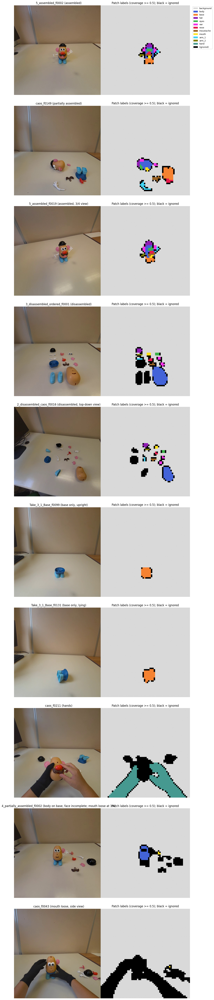

In [17]:
# 5.4 Visual Check
# on all reference frames: small pieces prevail over the body, mixed patches form a thin frame.
legend = [mpatches.Patch(color=CLASS_COLORS[n], label=n) for n in CLASS_NAMES] + \
         [mpatches.Patch(color="black", label="(ignored)")]

fig, axes = plt.subplots(len(REFERENCE_FRAMES), 2, figsize=(12, 6 * len(REFERENCE_FRAMES)))
for row, ref in zip(axes, REFERENCE_FRAMES):
    image = Image.open(ref["image_path"]).convert("RGB").resize(ref["resized_size"])
    label_rgb = cv2.resize(label_grid_to_rgb(ref["patch_labels"]), ref["resized_size"],
                           interpolation=cv2.INTER_NEAREST)
    row[0].imshow(image)
    row[0].set_title(f"{ref['frame']} ({ref['role']})")
    row[1].imshow(label_rgb)
    row[1].set_title(f"Patch labels (coverage >= {MIN_LABEL_COVERAGE}); black = ignored")
    for ax in row:
        ax.axis("off")

axes[0, 1].legend(handles=legend, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

Observation 5.4: In every reference frame, each visible piece is either labelled or ignored (black): no piece ends up in the background. Mounted pieces stay separate from the body, as the painting order intends.

The ignored patches form a thin frame around each piece. Thin pieces such as the arms are mostly frame, so they give fewer examples than their size suggests.

In the two disassembled frames, shoes and pants are fully black (old labels), and in the hands frame the pieces held in hand are black too. In 4_partially_assembled_f0002 only body and mouth are labelled, and in caos_f0043 only the mouth: there, seen from the side, it covers at least half of a single patch, so it gives one example. The two frames together add 4 mouth patches (28 against 24 with the previous eight frames).

------------------------------------------------------------------------------------------------------------------------------------------

References Section 5:

Russell et al. 2008, LabelMe, Sect. 3.3: overlapping polygons; an object completely contained in another one is on top 5.1.

Everingham et al. 2010, PASCAL VOC, Sect. 3.6.1: a 5-pixel void border around each object, labelled neither object nor background; Sect. 4.2.1: void pixels excluded from the evaluation 5.2.

Cordts et al. 2016, Cityscapes, Sect. 2.2: void label when a region is unclear, ignored in training and evaluation 5.2.

Tool: labelme (K. Wada, github.com/wkentaro/labelme), used for the polygon annotations.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 6 - Prototype construction and saving

This section builds one prototype per class from the reference frames.

A prototype is the mean of the feature vectors of a class, as in prototypical networks (Snell et al. 2017, Sect. 2.2) and in the nearest class mean classifier (Mensink et al. 2013, Sect. 3). Chen et al. show that a simple distance-based classifier on fixed features is competitive with more complex few-shot methods, and that a deeper backbone reduces the differences between methods (Chen et al. 2019, Sect. 1). With a strong model like C-RADIO, the simplest choice is reasonable.

Classification uses cosine similarity, so only the direction of a vector matters. Each patch vector is normalized before the mean, and the mean is normalized again. This is the maximum-likelihood mean direction of a von Mises-Fisher distribution, the distribution of unit vectors around a mean direction (Banerjee et al. 2005, Sect. 2.2, Eq. 2.4). It is also how weight imprinting turns a few examples of a new class into classifier weights (Qi et al. 2018, Sect. 4.2).

All the patches of a class are pooled across frames with the same weight, so a frame where a piece is large counts more (6.3). Ignored patches never enter a prototype.

A single mean assumes that the examples of a class form one group in feature space (Qi et al. 2018, Sect. 4.2). This holds less for the background, which mixes wall, table and floor, and for base, seen in two poses.

Prototypes are saved with their metadata (6.4) so that the studies can reuse them. Appendix A.1 compares the normalized mean with a plain mean.

In [18]:
# 6.1 Feature extraction for all reference frames
for ref in REFERENCE_FRAMES:
    image = Image.open(ref["image_path"]).convert("RGB")
    ref["features"], resized_size = extractor.extract(image)
    assert resized_size == ref["resized_size"], f"Resolution mismatch in {ref['frame']}"
    assert ref["features"].shape[:2] == ref["patch_labels"].shape, f"Grid mismatch in {ref['frame']}"

print(f"Features extracted for {len(REFERENCE_FRAMES)} reference frames, "
      f"grid {ref['features'].shape[1]}x{ref['features'].shape[0]}, D = {ref['features'].shape[2]}")

Features extracted for 8 reference frames, grid 64x64, D = 1152


In [19]:
# 6.2 Prototype construction: normalized mean, patch-weighted (build_prototypes in src/perception/prototypes.py)
prototypes, prototype_patch_counts = build_prototypes(REFERENCE_FRAMES)

missing = [name for name in CLASS_NAMES if name not in prototypes]
assert not missing, f"No patches for classes: {missing}"
print(f"{len(prototypes)} prototypes built, each a unit vector of dimension {len(next(iter(prototypes.values())))}")

12 prototypes built, each a unit vector of dimension 1152


In [20]:
# 6.3 Patches per class and per reference frame
count_table = pd.DataFrame(
    {ref["frame"]: [int((ref["patch_labels"] == i).sum()) for i in range(len(CLASS_NAMES))]
     for ref in REFERENCE_FRAMES},
    index=CLASS_NAMES,
)
count_table["total"] = count_table.sum(axis=1)
display(count_table)

,5_assembled_f0002,caos_f0149,5_assembled_f0019,3_disassembled_ordered_f0001,2_disassembled_caos_f0016,Take_3_1_Base_f0099,Take_3_1_Base_f0131,caos_f0211,total
background,3962,3850,3954,3733,3858,4036,4017,3288,30698
body,20,40,25,109,57,0,0,0,251
base,20,59,17,0,0,47,58,0,201
hat,11,8,14,10,9,0,0,0,52
eyes,8,6,8,6,4,0,0,0,32
ear,11,11,13,10,7,0,0,0,52
nose,5,10,6,5,3,0,0,0,29
moustache,5,12,8,5,5,0,0,0,35
mouth,4,6,4,6,4,0,0,0,24
arm_1,5,16,5,4,3,0,0,0,33


Observation 6.3: Some classes depend heavily on one frame. 48% of the arm_1 patches come from caos_f0149, where the arm is close to the camera, and 43% of the body patches come from 3_disassembled_ordered_f0001.

In the assembled frames the figure is small, so each small piece gives only 4 to 14 patches. arm_2 is the poorest class, with 15 patches from 4 frames. Hand has 482 patches, but all from a single frame.

The number of patches does not give a class more weight in classification, since every prototype is a unit vector. Fewer patches, however, make a prototype less representative.

In [21]:
# 6.4 Save prototypes and metadata, so other notebooks (e.g. the margin study) can reuse them
prototype_names = [name for name in CLASS_NAMES if name in prototypes]
metadata = {
    "created": time.strftime("%Y-%m-%d %H:%M"),
    "model": MODEL_DIR.name,
    "patch_size": PATCH_SIZE,
    "feature_dim": int(len(prototypes[prototype_names[0]])),
    "prototype_rule": "normalized mean of L2-normalized patch features, patch-weighted",
    "min_label_coverage": MIN_LABEL_COVERAGE,
    "reference_frames": [{"frame": r["frame"], "role": r["role"], "use_labels": sorted(r["use_labels"])}
                         for r in REFERENCE_FRAMES],
}

save_prototypes(PROTOTYPES_PATH, prototypes, prototype_patch_counts, metadata)

# Round-trip check: reload and compare
loaded = load_prototypes(PROTOTYPES_PATH)
assert loaded["class_names"] == prototype_names
assert np.allclose(loaded["prototypes"], np.stack([prototypes[name] for name in prototype_names]))
print(f"Saved {len(prototype_names)} prototypes to {PROTOTYPES_PATH}")


Saved 12 prototypes to c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_perception\prototypes.npz


------------------------------------------------------------------------------------------------------------------------------------------

References Section 6:

Snell et al. 2017, Prototypical Networks, Sect. 2.2, Eq. (1): the prototype is the mean of the embedded support points of its class.

Mensink et al. 2013, Sect. 3, Eq. (1): nearest class mean, each class represented by the mean of its examples.

Chen et al. 2019, A Closer Look at Few-shot Classification, Sect. 1: a distance-based classifier on fixed features is competitive with more complex few-shot methods; deeper backbones reduce the differences between methods.

Banerjee et al. 2005, Sect. 2.2, Eq. (2.4): the normalized mean is the maximum-likelihood mean direction of a von Mises-Fisher distribution.

Qi et al. 2018, Low-Shot Learning with Imprinted Weights, Sect. 4.2: average of normalized embeddings, normalized again; it assumes one group per class.

Normalization, patch norms and the labelling rule are verified in Appendix A.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 7 - Support-set gallery

This section shows what each prototype is actually made of. Table 6.3 counts the patches, but it does not show which parts of a piece survive the labelling rule of Section 5.

The gallery has one row per class and one column per reference frame. Each crop shows the annotated polygon in yellow (pixel level) and, at full brightness, the 16x16 patches that enter the prototype; everything else is dimmed. An empty cell means that the frame does not provide that class.

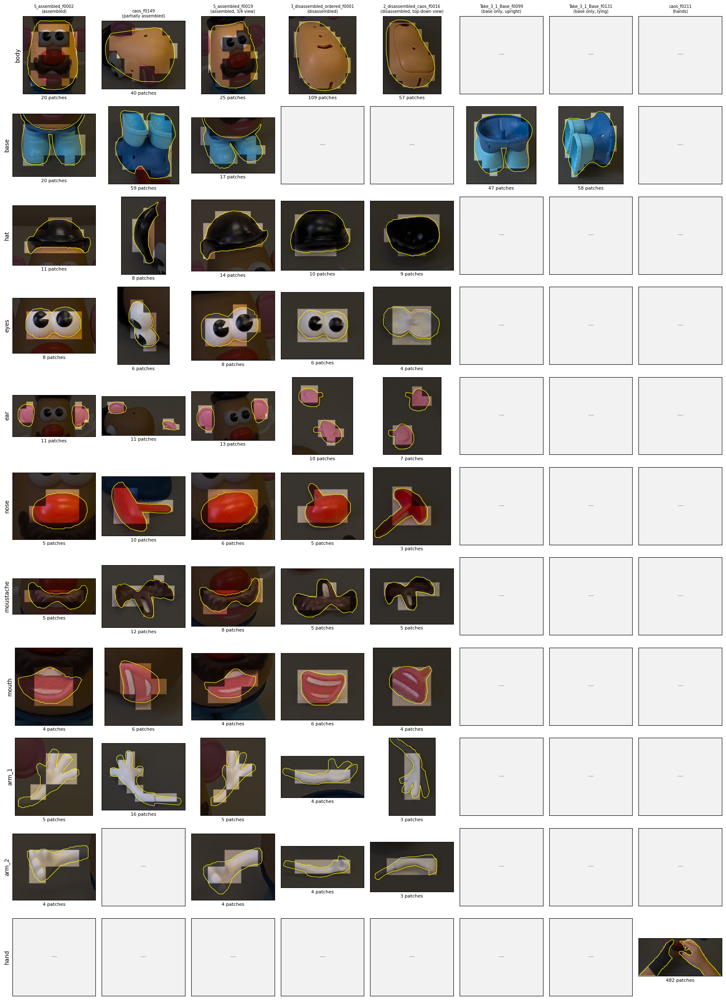

In [22]:
# 7.1 Support-set gallery: how each class appears in each reference frame.
# Rows = classes, columns = reference frames. Each crop shows the piece with the patches
# that enter its prototype at full brightness; everything else is dimmed.
gallery_classes = [name for name in CLASS_NAMES if name != BACKGROUND_LABEL]
resized_images = {
    ref["frame"]: np.asarray(Image.open(ref["image_path"]).convert("RGB").resize(ref["resized_size"]),
                             dtype=np.float32) / 255
    for ref in REFERENCE_FRAMES
}

fig, axes = plt.subplots(len(gallery_classes), len(REFERENCE_FRAMES),
                         figsize=(2.2 * len(REFERENCE_FRAMES), 2.2 * len(gallery_classes)))

annotations = {ref["frame"]: load_annotation(ref["json_path"]) for ref in REFERENCE_FRAMES}
for r, name in enumerate(gallery_classes):
    class_id = CLASS_NAMES.index(name)
    for c, ref in enumerate(REFERENCE_FRAMES):
        ax = axes[r, c]
        ax.set_xticks([])
        ax.set_yticks([])
        mask = ref["patch_labels"] == class_id

        if not mask.any():
            # This frame does not provide this class
            ax.set_facecolor("0.95")
            ax.text(0.5, 0.5, "—", ha="center", va="center", color="0.6", transform=ax.transAxes)
        else:
            # Crop: bounding box of the class patches, plus a margin (in patches)
            rows, cols = np.where(mask)
            h_p, w_p = mask.shape
            r0, r1 = max(rows.min() - GALLERY_MARGIN, 0), min(rows.max() + 1 + GALLERY_MARGIN, h_p)
            c0, c1 = max(cols.min() - GALLERY_MARGIN, 0), min(cols.max() + 1 + GALLERY_MARGIN, w_p)

            # Patch mask -> pixel mask; dim every pixel that is not in a prototype patch
            pixel_mask = np.kron(mask, np.ones((PATCH_SIZE, PATCH_SIZE)))[..., None]
            shown = resized_images[ref["frame"]] * np.where(pixel_mask, 1.0, GALLERY_DIM_FACTOR)
            ax.imshow(shown[r0 * PATCH_SIZE:r1 * PATCH_SIZE, c0 * PATCH_SIZE:c1 * PATCH_SIZE])
            ax.set_xlabel(f"{mask.sum()} patches", fontsize=8)
            # Overlay the original polygon outline (pixel-precise annotation) on the patch view
            ann = annotations[ref["frame"]]
            scale_x = ref["resized_size"][0] / ann["imageWidth"]
            scale_y = ref["resized_size"][1] / ann["imageHeight"]
            for shape in ann["shapes"]:
                if shape["label"] != name:
                    continue
                pts = np.array(shape["points"] + [shape["points"][0]])       # close the polygon
                ax.plot(pts[:, 0] * scale_x - c0 * PATCH_SIZE, pts[:, 1] * scale_y - r0 * PATCH_SIZE,
                        color="yellow", linewidth=0.8)
            ax.set_xlim(-0.5, (c1 - c0) * PATCH_SIZE - 0.5)
            ax.set_ylim((r1 - r0) * PATCH_SIZE - 0.5, -0.5)

        if r == 0:
            ax.set_title(f"{ref['frame']}\n({ref['role']})", fontsize=7)
        if c == 0:
            ax.set_ylabel(name, fontsize=10)

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "support_set_gallery.png", dpi=200, bbox_inches="tight")
plt.show()

Observation 7.1: Each class appears in different states and viewpoints across the reference frames: assembled, partially assembled, disassembled, seen from above. Base is seen upright and lying, while hand comes from one frame only.

In the assembled frames, the mounted pieces are cut out of the body, which contributes only the patches between them (5.1). The figure is small there, so each piece covers few patches (6.3).

Thin parts contribute only their central patches. The forearm of arm_1 never covers half a patch, so in the assembled frames arm_1 is represented mainly by its open hand. The nose seen from above gives only 3 patches.

Overall, the prototypes see mostly the centre of each piece and almost never its outline.

In the hands frame one hand is bare and the other wears a dark glove, so the hand prototype mixes two quite different appearances.

References Section 7: none (visualization of the support set)

## Section 8 - Prototype similarity

This section measures how different the prototypes are from each other, before any classification.

Each patch will take the class of the most similar prototype (Section 9). If two prototypes are close, a patch of one class is also close to the other, and a small change in the patch can switch its label. The similarity between prototypes is therefore a first indication of which classes will be confused.

It is only an indication: it compares the class means, not how spread out each class is.

8.1 shows the cosine similarity between every pair of prototypes, 8.2 the nearest class of each one.

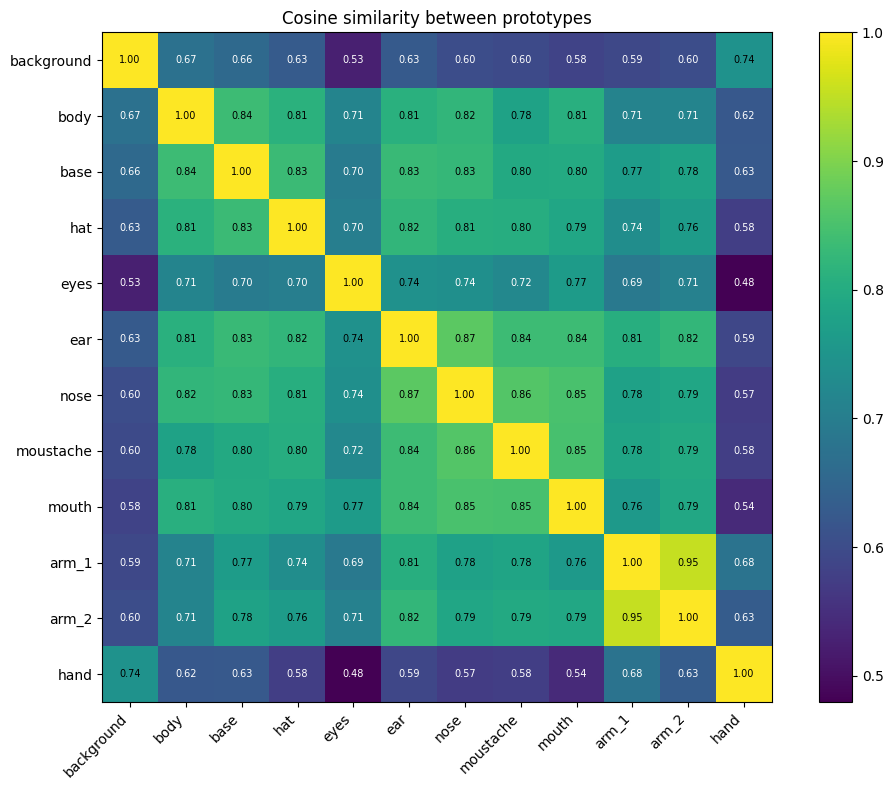

In [23]:
# 8.1 Prototype similarity matrix (cosine similarity between unit prototypes = dot product)
prototype_matrix = stack_prototypes(prototypes)
similarity = prototype_matrix @ prototype_matrix.T

off_diagonal = similarity[~np.eye(len(prototype_names), dtype=bool)]
vmin, vmax = off_diagonal.min(), 1.0
midpoint = (vmin + vmax) / 2

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(similarity, cmap="viridis", vmin=vmin, vmax=vmax)
ax.set_xticks(range(len(prototype_names)))
ax.set_xticklabels(prototype_names, rotation=45, ha="right")
ax.set_yticks(range(len(prototype_names)))
ax.set_yticklabels(prototype_names)
for i in range(len(prototype_names)):
    for j in range(len(prototype_names)):
        ax.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="black" if similarity[i, j] > midpoint else "white")
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title("Cosine similarity between prototypes")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "prototype_similarity.png", dpi=200, bbox_inches="tight")
plt.show()

Observation 8.1: The most similar pair is arm_1–arm_2 (0.95): same material, and from some viewpoints they differ only in the hand.

The small face pieces form a group (ear, nose, moustache, mouth: 0.84–0.87), with nose–ear as the closest pair despite their different colors. Body and base are as close as the face pieces (0.84), and hat is close to both. Eyes are the most distinctive piece: their nearest class, mouth, is at 0.77.

The background is far from all the pieces (0.53–0.67) and closest to hand (0.74). This matters little, since hand is never reported as a piece.

Apart from the two arms, all piece prototypes lie between 0.69 and 0.87: they share a high baseline similarity, so what matters are the differences between values, not the values themselves.

In [24]:
# 8.2 For each class: its nearest other class
nearest_similarity = similarity.copy()
np.fill_diagonal(nearest_similarity, -np.inf)

rows = []
for i, name in enumerate(prototype_names):
    j = int(nearest_similarity[i].argmax())
    rows.append({"class": name, "nearest class": prototype_names[j],
                 "cosine": similarity[i, j], "distance (1 - cosine)": 1 - similarity[i, j]})
nearest_table = pd.DataFrame(rows).set_index("class").sort_values("cosine", ascending=False)
display(nearest_table.round(4))

,nearest class,cosine,distance (1 - cosine)
class,,,
arm_1,arm_2,0.9545,0.0455
arm_2,arm_1,0.9545,0.0455
nose,ear,0.8685,0.1315
ear,nose,0.8685,0.1315
moustache,nose,0.8616,0.1384
mouth,nose,0.8507,0.1493
base,body,0.8361,0.1639
body,base,0.8361,0.1639
hat,base,0.8347,0.1653


Observation 8.2: The risky pairs for Section 9 are arm_1–arm_2 and the face-piece group. These are confusions between pieces, which the background margin does not address.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 8: none.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 9 - Classifier 

This section classifies the patches of new frames with the prototypes of Section 6.

Each patch vector is normalized and compared with the 12 prototypes by cosine similarity, and the patch takes the class of the most similar one. With unit vectors, the highest cosine is also the smallest Euclidean distance (Qi et al. 2018, Sect. 4.1), so this is the nearest class mean classifier (Mensink et al. 2013, Sect. 3) and the decision rule of prototypical networks (Snell et al. 2017, Sect. 2.2).

Only the ranking of the similarities matters, not their absolute value. When the first two classes are close, the decision is fragile (Section 8).

A margin then sends uncertain pieces to the background. If the winning piece beats the background by less than CONFIDENCE_MARGIN (0.03), the patch becomes background. Seeing a piece where there is none would mislead the later phases, so in doubt the patch is treated as background. The margin decides only between piece and background, never between two pieces. Its value is provisional and is the subject of a dedicated study.

The same function classifies the validation frames (Section 10) and the video (Section 11). The raw similarities of the validation frames are saved, so that the margin study can test any value without running C-RADIO again. Border artifacts (A.2) are not filtered: Section 10.2 shows that they are always classified as background.

In [25]:
# 9.1 Classifier: nearest prototype (cosine similarity) + background rejection margin
# (classify_patches in src/perception/prototypes.py)
assert prototype_names == CLASS_NAMES, "Prototype order must match CLASS_NAMES (colors, indices)"

In [26]:
# 9.2 Classify all validation frames and save raw similarities for the margin study
validation_results = {}
for val in VALIDATION_FRAMES:
    image = Image.open(val["image_path"]).convert("RGB")
    features, resized_size = extractor.extract(image)
    labels, similarities = classify_patches(features, prototype_matrix, CONFIDENCE_MARGIN)
    validation_results[val["frame"]] = {
        "labels": labels,
        "similarities": similarities,
        "norms": np.linalg.norm(features, axis=-1),   # kept for the border-artifact check (A.2)
        "resized_size": resized_size,
    }

np.savez_compressed(
    OUTPUT_DIR / "validation_similarities.npz",
    class_names=np.array(CLASS_NAMES),
    frames=np.array([v["frame"] for v in VALIDATION_FRAMES]),
    **{f"{frame}__similarities": r["similarities"].astype(np.float32) for frame, r in validation_results.items()},
    **{f"{frame}__norms": r["norms"].astype(np.float32) for frame, r in validation_results.items()},
)

summary = pd.DataFrame({
    v["frame"]: {name: int((validation_results[v["frame"]]["labels"] == i).sum()) for i, name in enumerate(CLASS_NAMES)}
    for v in VALIDATION_FRAMES
}).T
display(summary)


,background,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2,hand
assembly_2_f0003,3791,51,91,25,13,12,16,15,1,20,16,45
assembly_2_f0017,3824,79,55,26,14,16,24,15,7,28,8,0
assembly_2_f0046,3775,47,41,25,17,18,8,8,5,33,14,105
assembly_2_f0057,3772,35,36,30,16,30,7,10,5,30,18,107
assembly_2_f0068,3624,32,42,29,15,28,7,11,4,7,32,265
assembly_2_f0030,3431,70,42,22,16,16,14,5,11,2,9,458
1_disassembled_controlled_caos_f0001,3842,96,34,27,4,30,6,11,7,4,35,0
1_disassembled_controlled_caos_f0016,3808,91,25,35,0,25,6,8,2,4,29,63


Observation 9.2: Counts per class, a first coarse check. Hand is found when hands are in the frame (45–458 patches) and is absent otherwise (0 in assembly_2_f0017 and 1_disassembled_controlled_caos_f0001). The 63 hand patches in 1_disassembled_controlled_caos_f0016 are on the jeans (10.1).

In 1_disassembled_controlled_caos, arm_2 gets far more patches than arm_1 (35 vs 4, 29 vs 4), and eyes get few or none (4, 0). The counts in 10.1 (continued) show that most of these arm_2 patches are background around the loose pieces, while the arm patches themselves are mostly correct.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 9:

Qi et al. 2018, Sect. 4.1: with unit-length embeddings and templates, the highest inner product is the nearest template in squared Euclidean distance.

Mensink et al. 2013, Sect. 3: nearest class mean classifier.

Snell et al. 2017, Sect. 2.2: classification by distance to the class prototypes.

The background rejection margin is provisional; it is studied in a dedicated notebook.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 10 - Qualitative evaluation on validation frames
This section looks at the predictions on the 8 validation frames, which come from recordings never used for the prototypes (4.3). The evaluation is qualitative: the per-class IoU on the annotated frames is computed in the support-set study, and the margin will be chosen in the margin study. The test sequence (assembly_1) is not read.

10.1 shows the predicted labels for each validation sequence. Since the labels in a figure can be misleading, 10.1 (continued) counts what the patches of each annotated object are predicted as.

10.2 checks that the border artifacts of the model (A.2) are not predicted as pieces.

10.3 looks at one error that matters for anomaly detection: the empty mouth slot of the body is predicted as mouth. A missing piece seen as mounted would hide exactly the kind of anomaly the system must find, so we check whether the confidence of the classifier can tell the empty slot from a real mounted mouth.

10.4 runs the pipeline on a frame from a different camera, as a rough check of generalization.

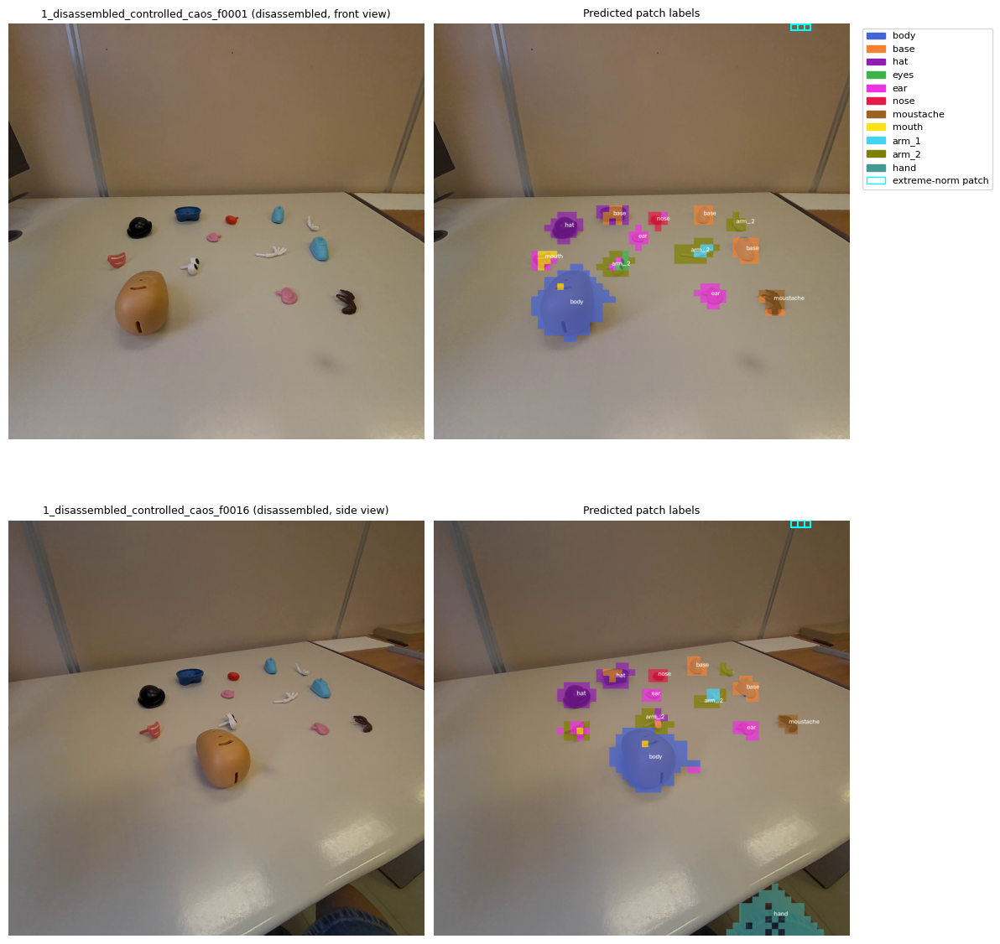

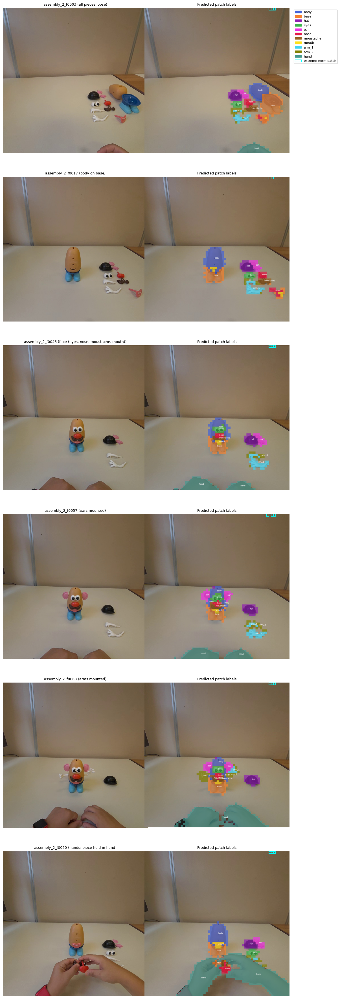

In [27]:
# 10.1 Predicted patch labels on the validation frames, one figure per validation sequence.
# render_overlay is in src/perception/visualization.py
# Cyan squares: extreme-norm patches (border artifacts, A.2).
legend = [mpatches.Patch(color=CLASS_COLORS[n], label=n) for n in CLASS_NAMES if n != BACKGROUND_LABEL] + \
         [mpatches.Patch(facecolor="none", edgecolor="cyan", label="extreme-norm patch")]

for sequence in sorted(VALIDATION_SEQUENCES):
    vals = [v for v in VALIDATION_FRAMES if v["sequence"] == sequence]
    fig, axes = plt.subplots(len(vals), 2, figsize=(12, 6 * len(vals)), squeeze=False)
    for (ax_image, ax_pred), val in zip(axes, vals):
        result = validation_results[val["frame"]]
        image = np.asarray(Image.open(val["image_path"]).convert("RGB").resize(result["resized_size"]))

        ax_image.imshow(image)
        ax_image.set_title(f"{val['frame']} ({val['stage']})", fontsize=9)
        ax_pred.imshow(render_overlay(image, result["labels"], MIN_BLOB_PATCHES))
        ax_pred.set_title("Predicted patch labels", fontsize=9)

        extreme = np.argwhere(result["norms"] > EXTREME_NORM_FACTOR * np.median(result["norms"]))
        for r, c in extreme:
            ax_pred.add_patch(mpatches.Rectangle((c * PATCH_SIZE, r * PATCH_SIZE), PATCH_SIZE, PATCH_SIZE,
                                                 fill=False, edgecolor="cyan", linewidth=1.5))
        for ax in (ax_image, ax_pred):
            ax.axis("off")

    axes[0, 1].legend(handles=legend, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"validation_predictions_{sequence}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [28]:
# 10.1 (continued): what the patches of each annotated object are predicted as
# (validation annotations, same labelling rule as the prototypes; border patches are ignored)
for val in VALIDATION_FRAMES:
    json_path = FRAMES_DIR / f"{val['frame']}.json"
    result = validation_results[val["frame"]]
    pixel_map = rasterize_annotation(json_path, set(CLASS_NAMES), result["resized_size"])
    gt_labels, _ = patch_label_grid(pixel_map, PATCH_SIZE, MIN_LABEL_COVERAGE)
    pred = result["labels"]

    print(f"\n{val['frame']} ({val['stage']})")
    for i, name in enumerate(CLASS_NAMES):
        mask = gt_labels == i
        if not mask.any():
            continue
        counts = pd.Series([CLASS_NAMES[k] for k in pred[mask]]).value_counts()
        if name == BACKGROUND_LABEL:
            counts = counts.drop(BACKGROUND_LABEL, errors="ignore")
            if not counts.empty:
                print("  background predicted as: " + ", ".join(f"{k} {v}" for k, v in counts.items()))
        else:
            print(f"  {name:10s} ({mask.sum():3d} patches): " + ", ".join(f"{k} {v}" for k, v in counts.items()))


assembly_2_f0003 (all pieces loose)
  background predicted as: nose 2, hat 1, ear 1, eyes 1, arm_2 1, base 1
  body       ( 39 patches): body 37, base 2
  base       ( 62 patches): base 62
  hat        ( 18 patches): hat 18
  eyes       (  8 patches): eyes 8
  ear        (  7 patches): ear 7
  nose       (  5 patches): nose 5
  moustache  (  8 patches): moustache 8
  mouth      (  8 patches): base 5, nose 2, mouth 1
  arm_1      ( 10 patches): arm_1 10
  arm_2      (  8 patches): arm_2 5, arm_1 3
  hand       ( 36 patches): hand 36

assembly_2_f0017 (body on base)
  background predicted as: body 7, base 5, hat 2, ear 1
  body       ( 69 patches): body 63, mouth 4, base 2
  base       ( 24 patches): base 23, body 1
  hat        ( 17 patches): hat 17
  eyes       (  6 patches): eyes 6
  ear        (  6 patches): ear 6
  nose       (  5 patches): nose 5
  moustache  (  8 patches): moustache 8
  mouth      (  8 patches): nose 5, mouth 3
  arm_1      ( 12 patches): arm_1 12
  arm_2      ( 

Observation 10.1: The figures show where the errors are, the counts how many and of which kind. Class names are written only on blobs of at least 5 patches (MIN_BLOB_PATCHES): small errors are colored but not named, and a name can come from patches of a nearby object. The labels in the figure can therefore be misleading, and the counts in 10.1 (continued) show what is actually predicted.

No piece is predicted on the wall or on the empty table. Mounted pieces are recognized in every frame of assembly_2, including the mounted mouth (3 of 3 patches in f0046 and f0057, 2 of 2 in f0068). Loose pieces seen from the front are recognized in f0003 and f0017. Pieces held in hand mostly keep their class in f0030: nose 10 of 10, moustache 4 of 6. The "base" label next to the moustache comes mostly from finger patches predicted as base. Hands are recognized.

Predicted pieces are larger than the real ones. Most false positives are background patches right next to a piece, and body patches around the mounted eyes are predicted as eyes (5 to 7 per frame). At inference every patch must take a class, including the border patches ignored when building the prototypes.

The loose mouth seen from the side is the weakest case: 1 of 8 patches correct in f0003 (5 as base, 2 as nose), 3 of 8 in f0017 (5 as nose), 1 of 4 in 1_disassembled_controlled_caos_f0016 (3 as ear). The loose eyes in 1_disassembled_controlled_caos are also missed (1 of 4 and 0 of 3 patches), but they cover very few patches.

Arms are confused with each other: in assembly_2, arm_2 is predicted mostly as arm_1 (4 of 6 patches in f0017, 7 of 8 in f0046, 6 of 8 in f0057). In 1_disassembled_controlled_caos the arm patches are mostly correct, but the background around the loose pieces is predicted as arm_2 (17 and 6 patches).

The empty mouth slot is predicted as mouth: 4 body patches in f0017 and 1 in each frame of 1_disassembled_controlled_caos, too few to be named in the figure.

Outside the pieces, the jeans in 1_disassembled_controlled_caos_f0016 are predicted as hand (63 patches). Separated shoes and pants, ignored in the ground truth, are predicted as base and hat (figure).

In [29]:
# 10.2 Are extreme-norm patches classified as pieces? (border artifacts, A.2)
rows = []
for val in VALIDATION_FRAMES:
    result = validation_results[val["frame"]]
    extreme = result["norms"] > EXTREME_NORM_FACTOR * np.median(result["norms"])
    predicted = [CLASS_NAMES[i] for i in result["labels"][extreme]]
    rows.append({
        "frame": val["frame"],
        "extreme patches": int(extreme.sum()),
        "positions": np.argwhere(extreme).tolist(),
        "predicted as": ", ".join(predicted) or "-",
    })
display(pd.DataFrame(rows).set_index("frame"))

,extreme patches,positions,predicted as
frame,,,
assembly_2_f0003,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
assembly_2_f0017,2,"[[0, 55], [0, 56]]","background, background"
assembly_2_f0046,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
assembly_2_f0057,3,"[[0, 54], [0, 56], [0, 57]]","background, background, background"
assembly_2_f0068,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
assembly_2_f0030,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
1_disassembled_controlled_caos_f0001,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
1_disassembled_controlled_caos_f0016,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"


Observation 10.2:
The extreme-norm border patches (A.2) are classified as background in all 8 validation frames: they cause no false positives, so no filtering is needed. They lie in the first row, columns 54–57.

In [30]:
# 10.3 Mouth on the empty slot: top1-top2 confidence
# Only mouth blobs touching body patches are measured: a loose mouth lying on the table is excluded.
MOUTH_ID, BODY_ID = CLASS_NAMES.index("mouth"), CLASS_NAMES.index("body")
EMPTY_SLOT_FRAME = "assembly_2_f0017"                                           # body on base, mouth not mounted yet
MOUNTED_MOUTH_FRAMES = ["assembly_2_f0046", "assembly_2_f0057", "assembly_2_f0068"]  # mouth mounted

from scipy import ndimage


def mouth_on_body(labels):
    """Patches predicted as mouth, in blobs that touch patches predicted as body."""
    blobs, _ = ndimage.label(labels == MOUTH_ID)
    near_body = ndimage.binary_dilation(labels == BODY_ID)
    keep = np.unique(blobs[near_body & (blobs > 0)])
    return np.isin(blobs, keep)

# Mouth predicted on the empty mouth slot: how close are mouth and body for those patches?
result = validation_results[EMPTY_SLOT_FRAME]
mouth_patches = mouth_on_body(result["labels"])
print(f"{EMPTY_SLOT_FRAME}: {mouth_patches.sum()} mouth patches touching the body")
if mouth_patches.any():
    sims = result["similarities"][mouth_patches]
    print(f"  mean similarity to mouth: {sims[:, MOUTH_ID].mean():.3f}")
    print(f"  mean similarity to body:  {sims[:, BODY_ID].mean():.3f}")
    print(f"  mean gap mouth - body:    {(sims[:, MOUTH_ID] - sims[:, BODY_ID]).mean():.3f}")

# Gap between the best and the second-best class for patches predicted as mouth:
# empty slot vs real mounted mouth
for frame in [EMPTY_SLOT_FRAME] + MOUNTED_MOUTH_FRAMES:
    result = validation_results[frame]
    mouth_patches = mouth_on_body(result["labels"])
    if not mouth_patches.any():
        print(f"{frame}: no patch predicted as mouth")
        continue
    sims = np.sort(result["similarities"][mouth_patches], axis=1)
    gap = sims[:, -1] - sims[:, -2]                     # best minus second best
    print(f"{frame}: {mouth_patches.sum():2d} mouth patches, "
          f"top1-top2 gap mean {gap.mean():.3f} (min {gap.min():.3f}, max {gap.max():.3f})")


assembly_2_f0017: 4 mouth patches touching the body
  mean similarity to mouth: 0.803
  mean similarity to body:  0.748
  mean gap mouth - body:    0.055
assembly_2_f0017:  4 mouth patches, top1-top2 gap mean 0.055 (min 0.019, max 0.091)
assembly_2_f0046:  5 mouth patches, top1-top2 gap mean 0.114 (min 0.077, max 0.146)
assembly_2_f0057:  5 mouth patches, top1-top2 gap mean 0.094 (min 0.014, max 0.166)
assembly_2_f0068: no patch predicted as mouth


Observation 10.3: Only mouth patches touching the body are measured, because in f0017 a loose mouth on the table is also partly predicted as mouth. In f0068 the mounted mouth is recognized (10.1), but it touches the moustache and the base, not the body, so this rule excludes it. The comparison therefore uses only f0046 and f0057.

On the empty slot (f0017, 4 patches), mouth beats body by 0.055 on average. On the mounted mouth the gap between the first and second class is larger on average: 0.114 in f0046, 0.094 in f0057.

Patch by patch, however, the ranges overlap: 0.019–0.091 on the empty slot, 0.014–0.166 on the mounted mouth. With so few patches, the top1–top2 gap does not separate the empty slot from a mounted mouth. This case is noted in the Limitations.

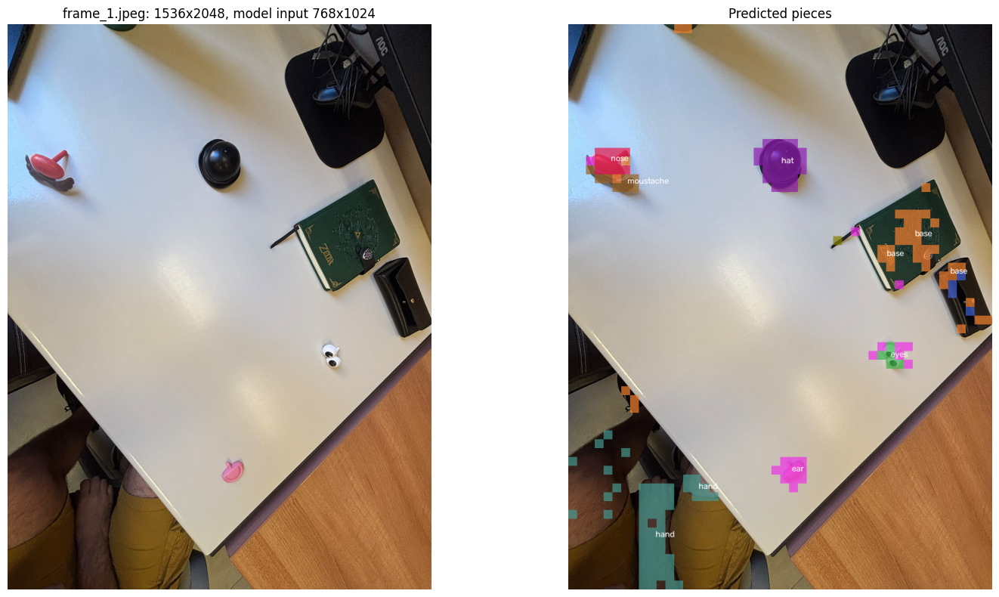

In [31]:
# 10.4 Independent frame from a different camera (iPhone, wide angle): qualitative check, no annotation.
# The image is first resized so that its longer side matches the headset frames (1024 px).
image = Image.open(INDEPENDENT_FRAME).convert("RGB")
original_size = image.size
image.thumbnail((INDEPENDENT_MAX_SIDE, INDEPENDENT_MAX_SIDE), Image.Resampling.LANCZOS)
features, resized_size = extractor.extract(image)
labels, _ = classify_patches(features, prototype_matrix, CONFIDENCE_MARGIN)
frame_rgb = np.array(image.resize(resized_size))

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(frame_rgb)
axes[0].set_title(f"{INDEPENDENT_FRAME.name}: {original_size[0]}x{original_size[1]}, "
                  f"model input {resized_size[0]}x{resized_size[1]}")
axes[1].imshow(render_overlay(frame_rgb, labels, MIN_BLOB_PATCHES))
axes[1].set_title("Predicted pieces")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "independent_frame_iphone.png", dpi=100, bbox_inches="tight")
plt.show()

Observation 10.4: Frame from a different camera (iPhone, wide angle), seen from above, with objects that never appear in the headset recordings. All the pieces present are recognized: hat seen from above, nose and moustache at an unusual angle, ear and eyes.

The unfamiliar objects, however, are not sent to background. The green notebook and the glasses case are predicted mostly as base, with a few body patches on the case, and the bare legs at the bottom are predicted as hand. A few isolated patches near the pen and the table edge take other classes.

Single frame, qualitative check only (no annotation): the pieces generalize to a new camera, but unfamiliar objects are mistaken for pieces.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 10: none.

Hypothesis: base may act as the default class for appearances the prototypes do not cover. In 10.4 the notebook and the glasses case, never seen in the recordings, are predicted mostly as base. In 10.1 the loose mouth seen from the side (f0003) and some finger patches (f0030) also go to base. In the support-set study (6.7), adding 5_assembled_f0019 moved some mouth, moustache and hand patches to base.

The margin study can only address the first case, where the true class is background. When the true class is another piece or the hand, the margin does not act: these patches are analysed in the support-set study, using the saved validation similarities to see whether the true class was a close second or far behind.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 11 - Video pipeline (motion gating)

This section runs the pipeline on a full validation video (assembly_2), to see how perception follows the assembly over time.

C-RADIO cannot run on every frame: one frame takes several hundred milliseconds (Section 12), against 33 ms between frames at 30 fps. Perception therefore runs only when the scene becomes still, once, and its prediction is shown while the scene stays still. A pause is also when the state of the assembly can be read, and a still frame has no motion blur.

The camera is head-mounted, so the image is never perfectly still: small head movements are always present. "Still" therefore means a motion score below MOTION_THRESHOLD (1.0 grey levels out of 255) for STABLE_FRAMES_NEEDED consecutive frames. The motion score is the mean absolute grey-level difference between consecutive frames, downscaled to 320x320. The threshold was set by watching the output on this video, so that perception starts at the pauses of the operator and not during hand movements. It has not been measured against annotated pauses: the gating is provisional and will be replaced by continuous perception.

The full video is saved in the outputs folder. 11.2 lists each C-RADIO run, and 11.3 shows one snapshot per run.

In [ ]:
# 11.1 Motion score between consecutive frames
def motion_score(prev_gray, gray):
    """Mean absolute grey-level difference (0-255) between two consecutive downscaled frames."""
    return float(np.abs(gray.astype(np.float32) - prev_gray.astype(np.float32)).mean())

In [33]:
# 11.2 Video pipeline: C-RADIO runs once each time the scene becomes still
DEMO_VIDEO = VIDEOS_DIR / "assembly_2.mp4"
assert DEMO_VIDEO.stem in VALIDATION_SEQUENCES, "The demo video must come from a validation sequence"

cap = cv2.VideoCapture(str(DEMO_VIDEO))
fps = cap.get(cv2.CAP_PROP_FPS)
width, height = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
output_video = OUTPUT_DIR / f"{DEMO_VIDEO.stem}_perception.mp4"
writer = cv2.VideoWriter(str(output_video), cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))

prev_gray, still_count, current_labels = None, 0, None
video_log, snapshots, motion_scores = [], [], []
frame_index = 0
while True:
    ok, frame_bgr = cap.read()
    if not ok:
        break
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.resize(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY), MOTION_SIZE)
    score = motion_score(prev_gray, gray) if prev_gray is not None else np.inf
    motion_scores.append(score)
    still_count = still_count + 1 if score < MOTION_THRESHOLD else 0
    prev_gray = gray

    if still_count == STABLE_FRAMES_NEEDED:          # the scene has just become still: run C-RADIO once
        features, _ = extractor.extract(Image.fromarray(frame_rgb))
        current_labels, _ = classify_patches(features, prototype_matrix, CONFIDENCE_MARGIN)
        counts = {CLASS_NAMES[i]: int((current_labels == i).sum()) for i in range(len(CLASS_NAMES))}
        video_log.append({
            "frame": frame_index,
            "time (s)": round(frame_index / fps, 2),
            "pieces seen": ", ".join(n for n, c in counts.items()
                                     if n not in (BACKGROUND_LABEL, HAND_LABEL) and c >= MIN_BLOB_PATCHES),
        })
        snapshots.append((frame_index, render_overlay(frame_rgb, current_labels, MIN_BLOB_PATCHES)))
    elif still_count < STABLE_FRAMES_NEEDED:
        current_labels = None                        # moving: no prediction is shown

    shown = render_overlay(frame_rgb, current_labels, MIN_BLOB_PATCHES) if current_labels is not None else frame_rgb.copy()
    status = "STILL - perception active" if current_labels is not None else "MOVING"
    cv2.putText(shown, status, (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2, cv2.LINE_AA)
    writer.write(cv2.cvtColor(shown, cv2.COLOR_RGB2BGR))
    frame_index += 1

cap.release()
writer.release()
print(f"{frame_index} frames processed, C-RADIO run {len(video_log)} times. Video saved to {output_video}")
pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(video_log))

2444 frames processed, C-RADIO run 33 times. Video saved to c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_perception\assembly_2_perception.mp4


,frame,time (s),pieces seen
0,5,0.17,"body, base, hat, eyes, ear, nose, moustache, arm_1, arm_2"
1,58,1.93,"body, base, hat, eyes, ear, nose, moustache, arm_1, arm_2"
2,71,2.37,"body, base, hat, eyes, ear, nose, moustache, arm_1, arm_2"
3,190,6.33,"body, base, hat, eyes, ear, nose, moustache, arm_1, arm_2"
4,205,6.83,"body, base, hat, eyes, ear, nose, moustache, arm_1, arm_2"
5,265,8.83,"body, base, hat, eyes, ear, nose, moustache, arm_1, arm_2"
6,372,12.40,"body, base, ear, arm_1, arm_2"
7,453,15.10,"body, base, hat, eyes, ear, nose, moustache, mouth, arm_1, arm_2"
8,465,15.50,"body, base, hat, eyes, ear, nose, moustache, mouth, arm_1, arm_2"
9,615,20.50,"body, base, hat, eyes, ear, nose, moustache, mouth, arm_2"


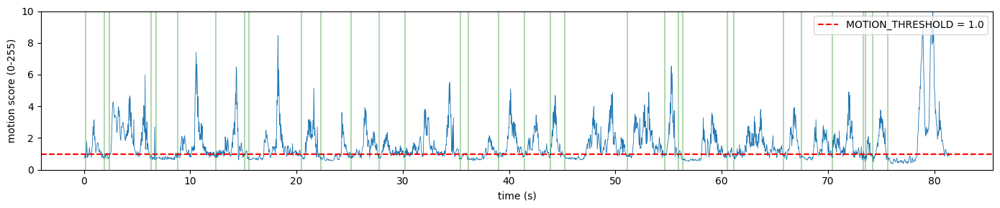

Frames below the threshold: 38%
Motion score percentiles 10/50/90: [0.68 1.17 2.91]


In [34]:
# 11.2 (continued) Motion score over the video, with the threshold and the C-RADIO runs
times = np.arange(len(motion_scores)) / fps
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(times, motion_scores, linewidth=0.6)
ax.axhline(MOTION_THRESHOLD, color="red", linestyle="--", label=f"MOTION_THRESHOLD = {MOTION_THRESHOLD}")
for run in video_log:
    ax.axvline(run["time (s)"], color="green", alpha=0.3)
ax.set_ylim(0, 10)
ax.set_xlabel("time (s)")
ax.set_ylabel("motion score (0-255)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

finite = np.array([s for s in motion_scores if np.isfinite(s)])
print(f"Frames below the threshold: {(finite < MOTION_THRESHOLD).mean():.0%}")
print(f"Motion score percentiles 10/50/90: {np.percentile(finite, [10, 50, 90]).round(2)}")

Observation 11.2: In about 81 s of video (2444 frames at 30 fps), C-RADIO runs 33 times. Close triggers in the same state (e.g. frames 2199, 2205, 2226) are explained in 11.2 (continued).

The "pieces seen" column lists a class when it has at least 5 patches in the frame. It is only a rough indicator: it can include false positives (for example arm_2 on the background) and miss small errors (the empty mouth slot has 4 patches). Almost every class appears at every run, because loose pieces on the table are counted too. Telling mounted from loose pieces requires their position relative to the body, which is the task of the next phase.

Observation 11.2 (continued): Hand movements give clear peaks of the motion score (2 to 9). During pauses the score does not drop to zero: head micro-movements keep it between about 0.6 and 1.2, and only a few stretches stay clearly below 1 (around 7–9 s, 56–58 s, 75–78 s).

The threshold (1.0) lies inside this background level: the 10th percentile is 0.68 and the median 1.17, and only 38% of the frames are below the threshold. Within a pause the score crosses the threshold back and forth, so perception starts whenever it stays below for 5 frames. This explains the close triggers in the same state (73.3, 73.5 and 74.2 s).

The threshold separates large movements from pauses, but it is unstable within a pause. A slightly higher value would make pauses more stable; it is left unchanged, since the gating is provisional.

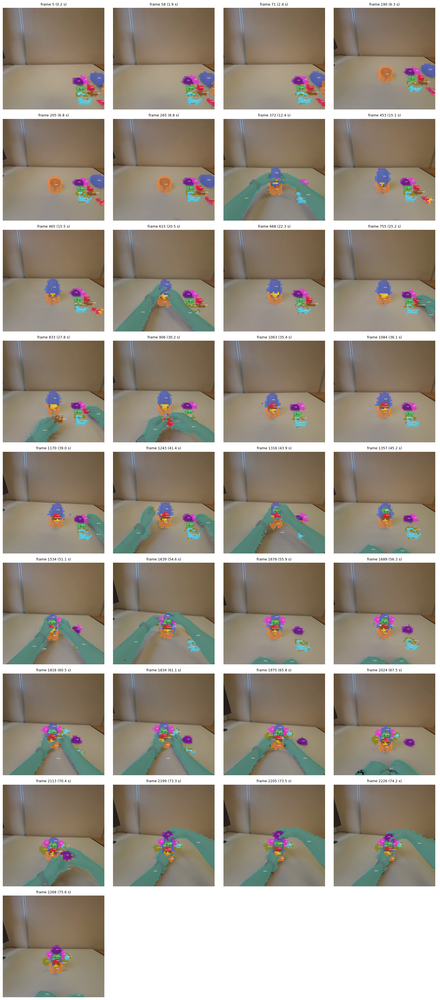

In [35]:
# 11.3 Snapshots of each moment C-RADIO was run (the full video is in the outputs folder)
n_cols = 4
n_rows = int(np.ceil(len(snapshots) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, (index, image) in zip(axes.flat, snapshots):
    ax.imshow(image)
    ax.set_title(f"frame {index} ({index / fps:.1f} s)", fontsize=9)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / f"{DEMO_VIDEO.stem}_snapshots.png", dpi=120, bbox_inches="tight")
plt.show()

Observation 11.3: The snapshots follow the whole assembly of assembly_2: all pieces loose (0.2–2.4 s), base alone (6.3 s), body on base (12.4 s), mouth (22.3 s), nose and moustache joined in hand (27.8–30.2 s) and then mounted on the face (35.4 s), eyes (45.2 s), ears (51.1 s), arms (60.5 s), hat (75.6 s). Each piece appears mounted at the right moment, and hands are recognized when present.

Pieces held in hand mostly keep their class (27.8–30.2 s; see the counts of f0030 in 10.1). The errors are those of Section 10: arms mixed between arm_1 and arm_2, both loose and mounted; the empty mouth slot predicted as mouth before the mouth is mounted (15.1–15.5 s); a mouth lying on its side predicted as nose or base.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 11: none. The motion gating is a simple frame difference with provisional parameters.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 12 - End-to-end latency

This section measures how long each step of the pipeline takes, to know whether perception could run on every frame. At 30 fps the budget is about 33 ms per frame.

Each step is timed on one validation frame, as the mean of 50 runs after 5 warm-up runs: the first GPU runs are slower because of memory allocation and kernel selection. The GPU works asynchronously, so the timer waits for it to finish before and after each step. C-RADIO is timed both alone and with the image preparation. Overlay rendering is measured separately: it is visualization, not perception.

In [36]:
# 12.1 Latency of each pipeline step on one validation frame (GPU warm-up excluded)
N_WARMUP, N_RUNS = 5, 50
latency_image = Image.open(VALIDATION_FRAMES[0]["image_path"]).convert("RGB")
latency_rgb = np.asarray(latency_image)
latency_gray = cv2.resize(cv2.cvtColor(latency_rgb, cv2.COLOR_RGB2GRAY), MOTION_SIZE)


def timed(fn):
    """Run fn and return (result, elapsed milliseconds), waiting for the GPU before and after."""
    torch.cuda.synchronize()
    start = time.perf_counter()
    result = fn()
    torch.cuda.synchronize()
    return result, (time.perf_counter() - start) * 1000


def model_forward(pixel_values):
    with torch.no_grad(), torch.autocast(DEVICE, dtype=DTYPE):
        return model(pixel_values)


# Model input computed once, to time the forward pass alone
pixel_values, _ = extractor.preprocess(latency_image)

# Warm-up: the first GPU runs are slower (memory allocation, kernel selection) and are not measured
for _ in range(N_WARMUP):
    features, _ = extractor.extract(latency_image)
    labels, _ = classify_patches(features, prototype_matrix, CONFIDENCE_MARGIN)

steps = {
    "motion score (every frame)":           lambda: motion_score(latency_gray, latency_gray),
    "C-RADIO forward only":                 lambda: model_forward(pixel_values),
    "feature extraction (preproc + model)": lambda: extractor.extract(latency_image),
    "classification":                       lambda: classify_patches(features, prototype_matrix, CONFIDENCE_MARGIN),
    "overlay rendering (visualization)":    lambda: render_overlay(latency_rgb, labels, MIN_BLOB_PATCHES),
}
timings = {name: [timed(fn)[1] for _ in range(N_RUNS)] for name, fn in steps.items()}

latency_table = pd.DataFrame({
    name: {"mean (ms)": np.mean(t), "std (ms)": np.std(t)} for name, t in timings.items()
}).T
perception_ms = latency_table.loc["feature extraction (preproc + model)", "mean (ms)"] + \
                latency_table.loc["classification", "mean (ms)"]
display(latency_table.round(2))
print(f"Perception (extraction + classification): {perception_ms:.1f} ms  ->  {1000 / perception_ms:.1f} fps")
print(f"GPU: {torch.cuda.get_device_name(0)}")

,mean (ms),std (ms)
motion score (every frame),0.63,1.12
C-RADIO forward only,357.80,1.47
feature extraction (preproc + model),380.15,4.10
classification,22.20,2.24
overlay rendering (visualization),57.46,6.60


Perception (extraction + classification): 402.4 ms  ->  2.5 fps
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


Observation 12.1: Observation 12.1: Perception (feature extraction and classification) takes about 400 ms per frame, 2.5 fps on this GPU at 1024x1024, far from the 30 fps of the video. Almost all of it is C-RADIO (about 360 ms, 90%); image preparation and classification take about 20 ms each, and the motion score less than 1 ms. The exact values of this execution are printed above.

With motion gating this is acceptable: the cost per frame is only the motion score, and pieces appear about 0.5 s after the scene becomes still (5 still frames, about 167 ms, plus perception). Continuous perception is not possible in this configuration. The options to study are a lower resolution, a stronger GPU (for example a server receiving frames from the headset), model optimization, or a lower target rate.

The standard deviations refer to the 50 runs within one execution. Between executions of the notebook the timings can differ much more on this laptop (an earlier run gave about 600 ms), possibly because of its power and thermal state.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 12: no new reference. Timings are specific to the GPU reported above.

------------------------------------------------------------------------------------------------------------------------------------------

## Limitations and next steps

Dataset. One operator and one environment, so the split is by recording and not by operator. Validation has 8 frames from two recordings, 6 of them from assembly_2, and the small pieces cover few patches. Hand comes from a single reference frame, with one bare and one gloved hand. In 1_disassembled_controlled_caos shoes and pants are separated, outside the base definition, so base is not evaluated there. assembly_1 (test) and assembly_2 (validation) were inspected once in v1-baseline, before any change to the method; from v1.1 on, this notebook reads only validation frames.

Recognition. Mounted pieces, loose pieces seen from the front and pieces held in hand are mostly recognized (10.1). The errors are concentrated in a few cases. A loose mouth seen from the side is predicted as base, nose or ear. Loose eyes in 1_disassembled_controlled_caos are missed. arm_1 and arm_2 are confused, with prototypes at 0.95 and only 15 patches for arm_2. The empty mouth slot is predicted as mouth, and the top1–top2 gap does not separate it from a mounted mouth (10.3). Predicted pieces are larger than the real ones, and unfamiliar objects are taken for pieces, often base (10.4).

Many of these errors involve appearances that differ from the average of their class: a mouth from the side, eyes from behind, a piece partly hidden by fingers. A single prototype per class assumes that each class forms one group in feature space (Qi et al. 2018, Sect. 4.2). The support-set study shows that adding reference frames moves these errors rather than removing them: a frame with the mouth on its side and one with the empty slot had no measurable effect, and every added frame shifted the boundary between the two arms.

Choices not studied. Input resolution (native 1024x1024; the model was also trained at 512). One prototype per class, built with a patch-weighted mean.

Provisional choices. The background margin (0.03), which only decides between piece and background: margin study. Motion gating: the threshold lies within the level of head micro-movements and is unstable within a pause (11.2); it will be replaced by continuous perception.

Latency. About 400 ms per frame at 1024x1024 on an RTX 4060 Laptop (2.5 fps), with large differences between executions of the notebook. Continuous perception needs a lower resolution, a stronger GPU, model optimization or a lower target rate.

Evaluation. Qualitative in this notebook. The quantitative evaluation (per-class IoU) is in the support-set study.

Next steps, in order: resolution study (1024 vs 512, recognition and latency); margin study; final evaluation on the test sequence (assembly_1), once; continuous perception; Phase 2, state tracking. Open questions for discussion: several prototypes per class, one per appearance, as in the nearest class multiple centroids classifier (Mensink et al. 2013); arm identity decided from the hand at object level (Phase 2); the empty mouth slot handled by the state of the assembly (Phase 2); the analysis of patches wrongly predicted as base (support-set study).

------------------------------------------------------------------------------------------------------------------------------------------

## Appendix A - Sensitivity checks

These checks verify choices made in Sections 5 and 6, and explain one anomaly of the model.

A.1 rebuilds the prototypes without normalizing the patches first, to see whether normalization changes the result. A.2 looks at the length (norm) of the patch vectors, finds a few extreme patches always at the same position, and tests whether they come from the images or from the model. A.3 rebuilds the prototypes with the center-pixel rule of 5.3, to see whether the labelling rule changes them.

In [37]:
# A.1 Raw vs normalized mean
raw_vs_normalized = {}
for name in prototype_names:
    raw_chunks = [ref["features"][ref["patch_labels"] == CLASS_NAMES.index(name)] for ref in REFERENCE_FRAMES]
    raw_pooled = np.concatenate([c for c in raw_chunks if len(c)])
    raw_prototype = l2_normalize(raw_pooled.mean(axis=0))          # alternative: mean of raw vectors
    norms = np.linalg.norm(raw_pooled, axis=1)
    raw_vs_normalized[name] = {
        "cosine(raw, normalized)": float(raw_prototype @ prototypes[name]),
        "patch norm CV": float(norms.std() / norms.mean()),       # how much patch lengths vary
    }
bg_norms_all = np.concatenate([np.linalg.norm(r["features"][r["patch_labels"] == 0], axis=-1) for r in REFERENCE_FRAMES])
bg_clean = bg_norms_all[bg_norms_all <= EXTREME_NORM_FACTOR * np.median(bg_norms_all)]
print(f"Background norm CV: {bg_norms_all.std() / bg_norms_all.mean():.3f} (all), "
      f"{bg_clean.std() / bg_clean.mean():.3f} (without extreme patches)")

display(pd.DataFrame(raw_vs_normalized).T.round(4))

Background norm CV: 0.578 (all), 0.045 (without extreme patches)


,"cosine(raw, normalized)",patch norm CV
background,0.9999,0.5779
body,1.0000,0.0495
base,1.0000,0.0581
hat,1.0000,0.0431
eyes,1.0000,0.0414
ear,0.9999,0.0471
nose,0.9999,0.0490
moustache,0.9996,0.0799
mouth,0.9998,0.0617
arm_1,1.0000,0.0496


Observation A.1: Raw and normalized means give practically the same prototypes (cosine ≥ 0.9996). The norms of the piece and hand patches vary little, with a coefficient of variation between 0.036 and 0.080, so normalizing changes almost nothing for them.

The background seems to vary much more (CV 0.578), but without the 24 extreme patches of A.2 its CV drops to 0.045, in line with the pieces. Normalization makes these patches weigh like any other patch and is consistent with cosine similarity. It is kept, and it does not change the result.

A.2 Patch norms. Distribution of patch-feature norms and test for fixed-pattern artifacts.

Median norm   background: 36.4   pieces: 38.4
Outlier threshold: 42.0
Background outliers: 117 / 30698 (0.38%)
  of which on the image border: 71%
  max outlier norm / median background norm: 29.0x
Register-related config entries: {'args.cpe_num_registers': None, 'args.register_multiple': 10, 'args.student_load_skip_state_dict_keys_regex': None, 'args.student_reinit_model_layers_regex': None, 'args.student_strict_load_ignore_mismatched_shape_keys_regex': None, 'args.student_strict_load_ignore_missing_keys_regex': None, 'args.student_strict_load_ignore_unexpected_keys_regex': None}
Parameters with 'reg' or 'cls_token' in the name: {'radio_model.model.patch_generator.cls_token.token': (10, 1152)}
Share of all patches on the border (expected if random): 12%
Extreme outliers (> EXTREME_NORM_FACTORx median): 24, of which on the border: 100%
5_assembled_f0002                [(0, 55), (0, 56), (0, 57)]
caos_f0149                       [(0, 55), (0, 56), (0, 57)]
5_assembled_f0019             

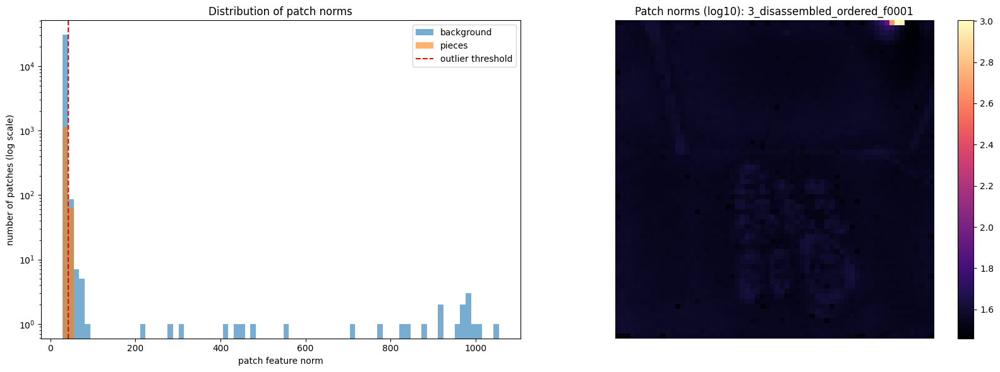

In [38]:
# A.2 Patch norms and fixed-pattern artifacts
all_norms, all_ids, on_border = [], [], []
for ref in REFERENCE_FRAMES:
    norms = np.linalg.norm(ref["features"], axis=-1)                 # (h, w): length of each patch vector
    border = np.zeros_like(norms, dtype=bool)
    b = PCA_BORDER_EXCLUDE
    border[:b, :] = border[-b:, :] = border[:, :b] = border[:, -b:] = True
    all_norms.append(norms.ravel())
    all_ids.append(ref["patch_labels"].ravel())
    on_border.append(border.ravel())
all_norms, all_ids, on_border = map(np.concatenate, (all_norms, all_ids, on_border))

bg_norms = all_norms[all_ids == 0]
piece_norms = all_norms[(all_ids > 0) & (all_ids < IGNORE_ID)]

# Outliers: Tukey's far-out fence (Q3 + 3*IQR), a standard, parameter-free definition
q1, q3 = np.percentile(bg_norms, [25, 75])
outlier_threshold = q3 + 3 * (q3 - q1)
is_bg_outlier = (all_ids == 0) & (all_norms > outlier_threshold)

print(f"Median norm   background: {np.median(bg_norms):.1f}   pieces: {np.median(piece_norms):.1f}")
print(f"Outlier threshold: {outlier_threshold:.1f}")
print(f"Background outliers: {is_bg_outlier.sum()} / {len(bg_norms)} ({is_bg_outlier.sum() / len(bg_norms):.2%})")
if is_bg_outlier.any():
    print(f"  of which on the image border: {on_border[is_bg_outlier].mean():.0%}")
    print(f"  max outlier norm / median background norm: {all_norms[is_bg_outlier].max() / np.median(bg_norms):.1f}x")

# Does this C-RADIO version use register tokens (the fix proposed by Darcet et al.)?
# They can appear in the nested config (args) and as extra rows of cls_token.
def find_keys(d, word, prefix=""):
    """Config entries whose key contains `word`, at any nesting level."""
    found = {}
    for k, v in d.items():
        if isinstance(v, dict):
            found.update(find_keys(v, word, f"{prefix}{k}."))
        elif word in str(k).lower():
            found[f"{prefix}{k}"] = v
    return found

print("Register-related config entries:", find_keys(model.config.to_dict(), "reg") or "none found in config")
print("Parameters with 'reg' or 'cls_token' in the name:",
      {n: tuple(p.shape) for n, p in model.named_parameters() if "reg" in n.lower() or "cls_token" in n.lower()})

# Plots: histogram + norm map of the example frame (same frame as the PCA in 3.6)
example_ref = next(r for r in REFERENCE_FRAMES if r["frame"] == EXAMPLE_FRAME.stem)
example_norms = np.linalg.norm(example_ref["features"], axis=-1)

extreme = (all_ids == 0) & (all_norms > EXTREME_NORM_FACTOR * np.median(bg_norms))
print(f"Share of all patches on the border (expected if random): {on_border.mean():.0%}")
print(f"Extreme outliers (> EXTREME_NORM_FACTORx median): {extreme.sum()}, of which on the border: {on_border[extreme].mean():.0%}")
# Are extreme patches always at the same grid positions? (position-dependent fixed-pattern noise)
extreme_threshold = EXTREME_NORM_FACTOR * np.median(bg_norms)
for ref in REFERENCE_FRAMES:
    rows, cols = np.where(np.linalg.norm(ref["features"], axis=-1) > extreme_threshold)
    print(f"{ref['frame']:<32} {list(zip(rows.tolist(), cols.tolist()))}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
bins = np.linspace(all_norms.min(), all_norms.max(), 80)
axes[0].hist(bg_norms, bins=bins, alpha=0.6, label="background", log=True)
axes[0].hist(piece_norms, bins=bins, alpha=0.6, label="pieces", log=True)
axes[0].axvline(outlier_threshold, color="red", linestyle="--", label="outlier threshold")
axes[0].set_xlabel("patch feature norm")
axes[0].set_ylabel("number of patches (log scale)")
axes[0].legend()
axes[0].set_title("Distribution of patch norms")

im = axes[1].imshow(np.log10(example_norms), cmap="magma")
axes[1].set_title(f"Patch norms (log10): {example_ref['frame']}")
axes[1].axis("off")
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

Extreme patches in a uniform grey image: [[0, 56], [0, 57], [0, 58]]


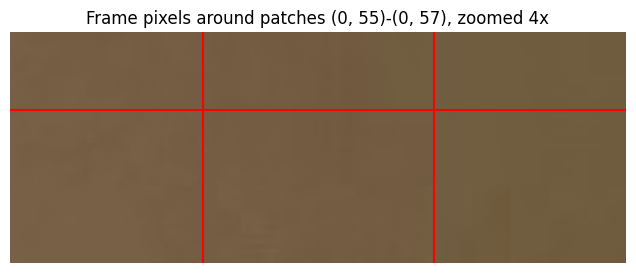

In [39]:
# A.2 (continued) Fixed-pattern test: uniform grey image
# Is the anomaly produced by the model (fixed-pattern noise) or by something in the frames?
# 1. Feed a uniform grey image: it has no content, so any anomaly comes from the model itself.
blank = Image.new("RGB", (1024, 1024), (128, 128, 128))
blank_features, _ = extractor.extract(blank)
blank_norms = np.linalg.norm(blank_features, axis=-1)
print("Extreme patches in a uniform grey image:",
      np.argwhere(blank_norms > EXTREME_NORM_FACTOR * np.median(blank_norms)).tolist())

# 2. Look at the pixels of that region in a real frame (patches (0, 55)-(0, 57) = x 880-928, y 0-16).
region = example_image.crop((840, 0, 968, 48)).resize((512, 192), Image.Resampling.NEAREST)
plt.figure(figsize=(8, 3))
plt.imshow(region)
plt.axvline((880 - 840) * 4, color="red")
plt.axvline((928 - 840) * 4, color="red")
plt.axhline(16 * 4, color="red")
plt.title("Frame pixels around patches (0, 55)-(0, 57), zoomed 4x")
plt.axis("off")
plt.show()

Observation A.2: Typical patch norms are similar for background and pieces (median 36.4 vs 38.4). 117 background patches (0.38%) exceed Tukey's far-out fence (Q3 + 3 IQR), 71% of them on the image border, against 12% of all patches.

24 of them are extreme, up to 29 times the median norm. They are always the same three patches, row 0, columns 55–57, in all 8 reference frames. The pixels there are plain wall, and a uniform grey image gives the same anomaly at row 0, columns 56–58: the artifact comes from the model, not from the images.

The C-RADIOv4 authors describe this kind of noise. Foundation models have position-dependent artifacts (DVT, Yang et al. 2024), SigLIP2 has "holes" along the border of its feature maps, and a student trained to imitate its teachers also learns this noise; their training reduces it with shift equivariance (tech report, Sect. 2.3, Fig. 2). Our extreme patches are consistent with a residual of this noise at the border.

Darcet et al. describe a different artifact of large ViTs, high-norm tokens on redundant background patches, and remove it with register tokens (Sect. 2 and 2.2). C-RADIOv4 already uses register tokens (register_multiple = 10 in its configuration, 10 prefix tokens in cls_token), and our extreme patches stay at the same position even on a uniform grey image. They point to the position-dependent noise above, not to the artifact of Darcet et al.

The extreme patches enter the background prototype, but after normalization they weigh like any other patch (A.1), and they are always classified as background (10.2), so no filtering is needed.

A.3 Labelling rule check. Prototypes are rebuilt with the center-pixel rule (5.3), using the same features and pixel maps: only the patch labelling rule changes. If the two versions are much closer to each other than two different classes are, the rule does not affect the prototypes.

In [40]:
# A.3 Does the labelling rule change the prototypes? Center-pixel rule vs coverage rule
center = PATCH_SIZE // 2

# Same features, same pixel maps: only the patch labelling rule changes.
# Alternative rule: each patch takes the label of its center pixel (IGNORE_ID and background included).
center_rule_frames = [
    {"features": ref["features"],
     "patch_labels": ref["pixel_map"][center::PATCH_SIZE, center::PATCH_SIZE]}
    for ref in REFERENCE_FRAMES
]
center_prototypes, center_patch_counts = build_prototypes(center_rule_frames)

rule_comparison = pd.DataFrame({
    name: {
        "patches (center pixel)": center_patch_counts[name],
        "patches (coverage >= 0.5)": prototype_patch_counts[name],
        "cosine(center, coverage)": float(center_prototypes[name] @ prototypes[name]),
    }
    for name in prototype_names
}).T
rule_comparison["patches (center pixel)"] = rule_comparison["patches (center pixel)"].astype(int)
rule_comparison["patches (coverage >= 0.5)"] = rule_comparison["patches (coverage >= 0.5)"].astype(int)
display(rule_comparison.round(4))

,patches (center pixel),patches (coverage >= 0.5),"cosine(center, coverage)"
background,31195,30698,1.0000
body,262,251,0.9999
base,204,201,0.9999
hat,51,52,0.9996
eyes,34,32,0.9997
ear,53,52,1.0000
nose,32,29,0.9991
moustache,36,35,0.9998
mouth,25,24,0.9998
arm_1,39,33,0.9989


In [41]:
# A.3 (continued) Labelling-rule shift vs distance to the nearest class (8.2)
nearest_table["rule shift"] = [1 - rule_comparison.loc[name, "cosine(center, coverage)"] for name in nearest_table.index]
nearest_table["distance / rule shift"] = nearest_table["distance (1 - cosine)"] / nearest_table["rule shift"].clip(lower=1e-6)
display(nearest_table.round(4))

,nearest class,cosine,distance (1 - cosine),rule shift,distance / rule shift
class,,,,,
arm_1,arm_2,0.9545,0.0455,0.0011,40.0182
arm_2,arm_1,0.9545,0.0455,0.0010,46.0877
nose,ear,0.8685,0.1315,0.0009,148.8749
ear,nose,0.8685,0.1315,0.0000,3013.2923
moustache,nose,0.8616,0.1384,0.0002,700.8333
mouth,nose,0.8507,0.1493,0.0002,697.0868
base,body,0.8361,0.1639,0.0001,2004.4840
body,base,0.8361,0.1639,0.0001,1499.5376
hat,base,0.8347,0.1653,0.0004,375.7221


Observation A.3: The labelling rule barely changes the prototypes: the cosine between center-pixel and coverage prototypes is at least 0.9989 for every class. The largest changes are for thin pieces (arm_1 0.9989, arm_2 0.9990, nose 0.9991).

These changes are at least 40 times smaller than the distance between each class and its nearest class (8.2). The coverage rule is kept because it keeps border patches out of the background prototype (5.3). Its effect on the validation results is measured in the support-set study (6.8), where the center-pixel rule lowers the mIoU.

------------------------------------------------------------------------------------------------------------------------------------------

References Appendix A:

C-RADIOv4 tech report, Sect. 2.3 and Fig. 2: a student learns the fixed-pattern noise of its teachers, SigLIP2 has artifacts along the border of its feature maps, and training reduces this noise with shift equivariance.

Yang et al. 2024, Denoising Vision Transformers (DVT), Abstract and Fig. 3: position-dependent artifacts in ViT features, caused by the positional embeddings.

Darcet et al. 2024, Vision Transformers Need Registers, Sect. 2 and 2.2: high-norm tokens on redundant background patches in large ViTs, removed by register tokens.

------------------------------------------------------------------------------------------------------------------------------------------